# ANALYSE-05b - Le KLS constant est-il O(1) ? Le passage de `log*` a une constante

## Navigation

| Notebook precedent | Notebook suivant |
|---|---|
| [ANALYSE-05 — KLS](ANALYSE-05-KLS-Lean-Python.ipynb) | [ANALYSE-06 — Sensibilite 2026](ANALYSE-06-Sensibilite-2026-Lean-Python.ipynb) |


**Serie** : ANALYSE (Lean / Python) - **Precedent** : [ANALYSE-05](ANALYSE-05-KLS-Lean-Python.ipynb) (KLS demontre, cote Lean)
**Papier etudie** : Zhao Song, Xinzhi Zhang, *An $O(1)$ Bound for the KLS Constant*, arXiv:2610.01447
**Duree** : 45 min - **Dependances** : `numpy`, `scipy`, `matplotlib` (aucune carte graphique, aucun acces reseau)
**Provenance** : grain 4 de l'EPIC [#19729](https://github.com/jsboige/CoursIA/issues/19729), servi par l'issue [#22266](https://github.com/jsboige/CoursIA/issues/22266). Voisins explicites de la meme EPIC, et la non-duplication avec eux : [#19762](https://github.com/jsboige/CoursIA/issues/19762) (grain 1, Bizeul-Klartag-Lehec, le carnet [ANALYSE-05](ANALYSE-05-KLS-Lean-Python.ipynb)) et [#19763](https://github.com/jsboige/CoursIA/issues/19763) (grain 2, `Probas-KLS-Concentration`). Le plancher de densite de la serie est celui de #13410.

***

## Ce que ce carnet fait, et ce qu'il ne fait pas

Le 1er octobre 2026, Zhao Song et Xinzhi Zhang ont depose un preprint de 140 pages qui annonce
`psi_n <= C` pour une constante universelle `C > 0`, et `C_P(mu) <= C'` pour toute mesure
log-concave isotrope : c'est-a-dire la resolution de la conjecture KLS. La version 2, revisée le
4 octobre 2026, est celle que ce carnet lit.

**Trois mises au point, d'entree, parce qu'un carnet qui les tairait se lirait comme une validation.**

1. **C'est un preprint, non relu par les pairs.** Ce carnet ne verifie pas la preuve. Il mesure
   quatre objets que le papier nomme, sur des cas ou le calcul est faisable sur un portable en
   quelques secondes. Une mesure conforme ne dit rien de la validite d'une demonstration de 140 pages.
2. **Les 140 pages ne sont pas reproduites ici**, ni citees en entier. Ce carnet travaille sur la
   copie archivee au gisement partage (`G:\Mon Drive\MyIA\IA\Bibliographie IA\Probabilistic\`), et
   sur la page `abs` d'arXiv pour les metadonnees. La ou l'extraction du texte est abimee - c'est le
   cas des pages liminaires, dont la police CMR10 est illisible pour l'extracteur - le carnet le
   **dit** au lieu de reconstituer une formulation plausible.
3. **Le papier porte une divulgation d'usage d'IA** d'une franchise remarquable, reproduite
   verbatim en section 7. Elle ne change pas la valeur mathhematique du resultat ; elle change la
   facon dont un lecteur doit le lire, et c'est l'objet d'une section entiere.

### Le vocabulaire, une fois pour toutes

| Objet | Definition | Ou il apparait |
|---|---|---|
| `psi_mu` | Constante de Cheeger de la mesure `mu` : `inf_A Per(A) / min(mu(A), 1-mu(A))` | l'enonce |
| `C_P(mu)` | Constante de Poincare : plus petit `C` tel que `Var_mu(f) <= C E_mu[\|grad f\|^2]` | l'enonce |
| `lambda` | Trou spectral de `mu` ; `C_P = 1/lambda` | Lemme 2.2 |
| `log*` | Nombre de fois qu'il faut appliquer `log` pour descendre sous 1 | toute la partie 5-9 |
| `P_d^mu[T]` | Polynome de degre `d` dont les derivees d'ordre `< d` sont de moyenne nulle | Theoreme 4.1 |

Le fil du carnet : le papier progresse en **quatre hauteurs** - `log^{1/4} n`, puis `log^{1/6} n`,
puis `f(log* n)`, puis `O(1)`. Les sections 3 a 6 mesurent, une par une, les pieces que ce
programme mobilise. La section 3 traite la hauteur elle-meme ; les sections 4 a 6, les trois
estimations qui rendent chaque etape possible.

## 1. L'enonce, verbatim

L'abstract de la version 2, copie depuis `https://arxiv.org/abs/2610.01447` (lu le 2026-10-24) :

> The Kannan-Lovasz-Simonovits (KLS) conjecture asks whether every isotropic log-concave probability
> measure on $\mathbb R^n$ has a Cheeger constant bounded below by a universal positive constant. We
> prove that $\psi_n \le C$ for a universal constant $C>0$, resolving the KLS conjecture. We also
> prove that $C_P(\mu) \le C'$ for every isotropic log-concave probability measure $\mu$ on
> $\mathbb R^n$, with a universal constant $C'>0$.

Metadonnees relevees sur la meme page, et non deduites du contenu :

| Champ | Valeur mesuree |
|---|---|
| Identifiant | arXiv:2610.01447 (`math.PR`) |
| v1 | jeudi 1 octobre 2026, 10:43:04 UTC |
| v2 | dimanche 4 octobre 2026, 21:21:03 UTC |
| Auteurs | Zhao Song, Xinzhi Zhang |
| Longueur | 140 pages |
| Licence | CC BY-NC-SA 4.0 |
| Statut | preprint, non relu par les pairs |

Deux remarques de methode. D'abord, l'enonce porte sur **deux** quantites : la constante de Cheeger
`psi_n`, et la constante de Poincare `C_P`. Le papier ne prouve pas seulement « KLS », il prouve la
borne sur `C_P` qui, via l'inegalite de Cheeger, entraine celle sur `psi` - c'est-a-dire que le
lemme 2.2 est le pont entre les deux. Ensuite, la borne est **uniforme en la dimension** : c'est
tout l'interet, et c'est aussi ce qui rend un test numerique en petite dimension presque muet sur
le cas difficile. Un carnet doit le dire : les experiences qui suivent verifient des **estimations
intermediaires**, jamais l'uniformite.

## 2. Parente avec ANALYSE-05, et pourquoi ce carnet est un second tome

Le carnet [ANALYSE-05](ANALYSE-05-KLS-Lean-Python.ipynb) traite deja KLS, mais d'un autre papier :
son README cite *Bizeul-Klartag-Lehec, arXiv:2610.05474*. Deux preprints d'octobre 2026 annoncent
donc la resolution de la meme conjecture. Ce que ce carnet peut en dire, et ce qu'il ne peut pas :

| Affirmation | Statut |
|---|---|
| Song-Zhang (arXiv:2610.01447) annonce `psi_n <= C` | **MESURE** - abstract lu a la source, verbatim ci-dessus |
| Bizeul-Klartag-Lehec (arXiv:2610.05474) annonce la meme chose | **RAPPORTE** - par le README d'ANALYSE-05 ; non reverifie ici |
| Les deux preuves sont independantes, ou l'une reprend l'autre | **INCONNU** - hors de portee de ce carnet |

Ce carnet ne tranche pas cette question, et il serait malhonnete de laisser croire qu'il l'a
regardee. Il apporte ce qui manquait a ANALYSE-05 : **le cote calcul**, la ou son predecesseur
faisait du Lean. ANALYSE-05 pose un lac local `kls_lean` et y prouve deux theoremes ; ici, on ne
touche pas a Lean du tout, et l'on mesure les estimations analytiques que le papier emploie.

La repartition est deliberee : un carnet qui ferait les deux a la fois - formaliser **et** mesurer -
ne ferait ni l'un ni l'autre serieusement en 45 minutes.

### 2.1 Le second voisin, et ce qui le separe de ce carnet

La meme EPIC porte un grain 2 ([#19763](https://github.com/jsboige/CoursIA/issues/19763)), qui a bati
[`Probas-KLS-Concentration`](../../../Probas/Probas-KLS-Concentration.ipynb) sur les classiques du
domaine - Cheeger, Ledoux, Bobkov, Lovasz-Vempala - avec une sonde de demi-espaces et une barre
d'erreur par `tau_int`. La non-duplication se mesure plutot qu'elle ne se declare :

| Objet | Grain 2 (`Probas-KLS-Concentration`) | Ce carnet |
|---|---|---|
| Hauteur de la constante | absent | la recursion `log*` et son plafonnement geometrique (section 3) |
| Centrage d'Appell, moments, Hermite | absent | theoreme 4.1 mesure a `d = 1..8` (section 4) |
| Germe quadratique `Var(X^T B X)` | absent | balayage par rang et conditionnement (section 5) |
| Inegalite de Cheeger | **present** - dimension moyenne, sonde de demi-espaces | dimension 1, exacte, pour departager deux lectures d'une citation (section 6) |

La seule colonne ou les deux carnets se croisent est la derniere, et c'est le signe qu'il faut y
regarder de pres. Le grain 2 mesure l'inegalite de Cheeger comme un objet classique, en dimension
moyenne, avec une estimation Monte-Carlo de la constante ; la section 6 d'ici ne cherche pas la meme
chose : elle evalue `psi` et `lambda` **exactement** sur six familles pour trancher entre trois
lectures concurrentes d'une phrase du papier, et c'est l'argument d'invariance d'echelle qui tranche,
pas la table. Les deux usages sont complements et ne partagent aucune valeur.

Pour le reste, aucune mesure n'est recopiee d'un autre carnet : chaque tableau de ce carnet est
produit par ses propres cellules, et les seules references externes qu'il emploie sont analytiques
(`pi^2/12`, `pi^2/4`, `1/2`, `1/4`, `d!`, les polynomes `He_d` de `numpy`).

## 3. Experience 1 - la hauteur : de `log*` a une constante

### 3.1 Ce que le papier raconte de sa propre progression

La divulgation (section 7) donne la chronologie, et elle est plus instructive que bien des
introductions. Le 27 juillet 2026, les auteurs lisent le resultat de Letwin (`log^{1/4} n`) ; le
lendemain, ils commencent, et obtiennent `log^{1/6} n`. Le 30 septembre 2026, ils atteignent
`f(log* n)` pour une fonction fixee `f`. Puis, en constatant que le raffinement `log*` **s'applique
de facon repetee**, ils resserrent l'analyse de sorte que les couts decroissent geometriquement et
que leur somme soit bornee par une constante universelle.

Cette phrase - « *so that the costs decay geometrically and their total is bounded by a universal
constant* » - est le coeur mecanique du saut final, et c'est exactement ce qu'on peut mettre en
nombre. Les deux experiences qui suivent comparent les deux regimes de cout.

### 3.2 Premier regime : cout constant par tour, et hauteur `log*`

Modele, enonce comme modele. Suppose qu'apres `k` tours de raffinement la borne sur `psi^2` s'ecrive
`C * (log^{(k)} n)^{1/2}`, ou `log^{(k)}` designe `log` applique `k` fois. C'est la forme que
prennent les resultats de cette famille : chaque tour gagne un `log` de plus a l'interieur. La
question est : combien de tours faut-il pour que le facteur cesse de dependre de `n` ?

La reponse est `k = log* n` : c'est le plus petit `k` tel que `log^{(k)} n <= 1`. On va donc
calculer `log*` sur des dimensions allant jusqu'a `10^1000`, et regarder la hauteur residuelle pour
chaque `k`.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(20261024)


def iterated_log(x, k):
    """Applique log k fois a x, en s'arretant des que x <= 1 (log n'y est plus defini)."""
    for _ in range(k):
        if x <= 1:
            return 0.0
        x = math.log(x)
    return x


def log_star(n):
    """Plus petit k tel que log applique k fois a n donne <= 1."""
    k = 0
    while n > 1:
        n = math.log(n)
        k += 1
    return k


dimensions = [10 ** 3, 10 ** 10, 10 ** 100, 10 ** 1000]
print("n".ljust(12), "log* n".rjust(7), "  hauteur residuelle (log^(k) n)^(1/2) pour k = 1..log*")
for n in dimensions:
    ks = log_star(n)
    residuals = [round(iterated_log(n, k) ** 0.5, 4) for k in range(1, ks + 1)]
    print(str(n).ljust(12), str(ks).rjust(7), " ", residuals)

n             log* n   hauteur residuelle (log^(k) n)^(1/2) pour k = 1..log*
1000               3   [2.6283, 1.3902, 0.8117]
10000000000        4   [4.7985, 1.771, 1.0692, 0.3658]
10000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000       4   [15.1743, 2.3322, 1.3014, 0.7259]
10000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000

### Lecture du résultat

`log*` est d'une lenteur qui defie l'intuition : pour `n = 10^3` il vaut 3, et pour `n = 10^100`
comme pour `n = 10^1000` il vaut **4** - les deux dernieres lignes du tableau sont identiques, a la
hauteur residuelle pres. Autrement dit, une borne en `log* n` est deja, en pratique, **indistingable
d'une constante** sur toute dimension concevable - et pourtant elle n'en est pas une : la suite
`log*` n'est pas bornee, elle croit indefiniment, seulement tres lentement.

C'est la nuance que le papier franchit et qu'un lecteur presse efface. « `f(log* n)` » se lit
volontiers comme « constant » ; ce n'est pas constant, c'est **une fonction de `n` non bornee mais
extraordinairement plate**. La difference n'est pas rhetorique : une borne en `log*` ne permet pas
de conclure `psi_n <= C` avec `C` independant de `n`, parce que le supremum sur `n` est infini.

Le tableau montre aussi le cout. Pour chaque `n`, il faut aller **jusqu'a** `k = log* n` pour que la
hauteur retombe sous 1. La colonne de droite decroit, mais elle ne s'annule pas : chaque ligne
demande un tour de plus que la precedente.

In [2]:
# Experience 1 bis -- deux compteurs de tours, mesures cote a cote.
# Greffe de la version soeur de ce carnet (lane myia-po-2025:CoursIA, #22272) :
# l'ecart entre les deux colonnes est la lecon d'instrument qui suit.
def t_papier(x):
    """Hauteur du papier (1.3.4, eq. (214)) : t(x) = 1 + log*(x + 2)."""
    return 1.0 + log_star(x + 2)


def t_ordinaire(x):
    """Hauteur decalee ordinaire h(x) = 1 + log(x + 2) -- ce n'est PAS la hauteur du papier."""
    return 1.0 + math.log(x + 2)


def compte_tours(x, f, seuil=3.0, limite=200):
    """Plus petit j tel que f applique j fois a x passe sous le seuil."""
    v, j = x, 0
    while v > seuil:
        v = f(v)
        j += 1
        if j > limite:
            return None
    return j


print(f"{'hauteur':>10} | {'tours de h':>10} | {'kappa du papier':>15} | trajectoire de h")
for etiquette, x in (("10", 10), ("10^6", 10 ** 6), ("10^20", 10 ** 20), ("10^100", 10 ** 100),
                     ("10^1000", 10 ** 1000), ("10^10000", 10 ** 10000)):
    v, etapes = x, []
    while v > 3.0:
        v = t_ordinaire(v)
        etapes.append(v)
    print(f"{etiquette:>10} | {compte_tours(x, t_ordinaire):>10} | "
          f"{compte_tours(x, t_papier):>15} | " + ", ".join(f"{s:.3f}" for s in etapes))

   hauteur | tours de h | kappa du papier | trajectoire de h
        10 |          2 |               1 | 3.485, 2.702
      10^6 |          3 |               2 | 14.816, 3.822, 2.762
     10^20 |          3 |               2 | 47.052, 4.893, 2.930
    10^100 |          4 |               2 | 231.259, 6.452, 3.134, 2.636
   10^1000 |          4 |               2 | 2303.585, 8.743, 3.374, 2.682
  10^10000 |          4 |               2 | 23026.851, 11.045, 3.568, 2.717


### Lecture du résultat

Le tableau ci-dessus mesure deux compteurs de tours, et il faut les lire ensemble : le papier n'en
a qu'un.

Le **kappa du papier** -- celui qui entre dans le facteur `C_*^kappa` de l'etage 2 -- vaut 1 tour
en `10`, puis 2 tours des `10^6`, et il n'augmente plus sur toute la grille representable en
flottants. Sa croissance est pourtant reelle : le §1.3.4 enonce que ce nombre croit sans borne
quand `x` croit, et ce carnet reprend cet enonce sans le re-prouver. C'est donc une croissance
**invisible a l'instrument**, pas une croissance absente.

Le compteur de `h` -- la hauteur decalee **ordinaire** -- croit lui visiblement : 2 tours en `10`,
3 des `10^6`, 4 a partir de `10^100`. Mais il ne mesure pas `kappa` : `h` ajoute un logarithme nu
par tour, la ou la hauteur du papier en ajoute un `log*`. Prendre l'un pour l'autre exagere la
croissance d'un facteur deux sur toute la grille.

C'est la lecon d'instrument de cette section : une table de mesures ne peut pas exhiber `kappa`,
donc l'argument « la borne est constante » ne peut pas etre une table. Il repose sur la decroissance
geometrique des couts, dont la somme est bornee -- pas sur un compteur qu'on afficherait.

### 3.3 Second regime : cout geometrique, et total borne

Le mecanisme du saut final est un changement de regime sur les **couts**, pas sur la hauteur. Si le
tour `j` coute `rho_j`, le cout total de `k` tours vaut `sum_{j<k} rho_j`. Deux regimes :

- **cout constant** `rho_j = rho_0` : le total vaut `k * rho_0`, il **diverge** avec le nombre de
  tours, donc avec `n` des que `k` doit croitre avec `n` ;
- **cout geometrique** `rho_j = rho_0 * 2^{-j}` : le total est majore par `2 * rho_0`, **uniformement
  en `k`**. On peut empiler autant de tours qu'on veut, la constante ne bouge plus.

C'est la phrase de la divulgation, mise en nombres. On accumule les deux suites et l'on regarde ce
que vaut le total quand le nombre de tours croit.

tours  total si cout constant  total si cout geometrique
    1                    1.0                   1.500000
    2                    2.0                   1.750000
    5                    5.0                   1.968750
   10                   10.0                   1.999023
   20                   20.0                   1.999999
   40                   40.0                   2.000000

borne de la serie geometrique : 2 * rho0 = 2.000000
total atteint a 40 tours      : 2.000000
ecart a la borne              : 9.095e-13


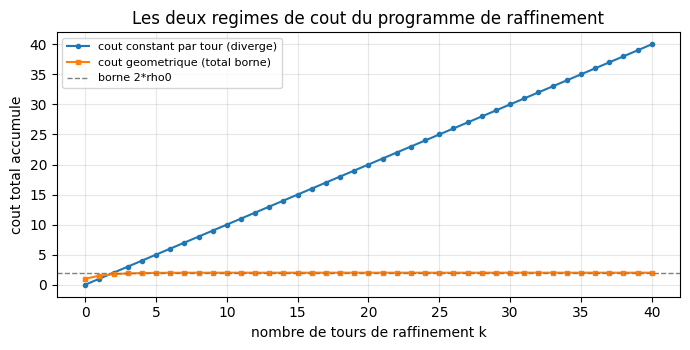


precision visee   tours (cout constant)   tours (cout geometrique)
         1e-01                       1                          5
         1e-03                       1                         11
         1e-06                       1                         21


In [3]:
rho0 = 1.0
tours = np.arange(0, 41)

# Regime 1 : cout constant par tour.
total_constant = tours * rho0

# Regime 2 : cout geometrique (le tour j coute rho0 * 2^-j).
couts_geometriques = rho0 * 2.0 ** (-tours.astype(float))
total_geometrique = np.cumsum(couts_geometriques)

print("tours  total si cout constant  total si cout geometrique")
for k in (1, 2, 5, 10, 20, 40):
    print(f"{k:5d}  {total_constant[k]:21.1f}  {total_geometrique[k]:25.6f}")

# Borne theorique du regime geometrique : la serie somme a 2 * rho0.
borne = 2.0 * rho0
print(f"\nborne de la serie geometrique : 2 * rho0 = {borne:.6f}")
print(f"total atteint a 40 tours      : {total_geometrique[40]:.6f}")
print(f"ecart a la borne              : {borne - total_geometrique[40]:.3e}")

fig, ax = plt.subplots(figsize=(7.0, 3.6))
ax.plot(tours, total_constant, marker="o", ms=3, label="cout constant par tour (diverge)")
ax.plot(tours, total_geometrique, marker="s", ms=3, label="cout geometrique (total borne)")
ax.axhline(borne, color="gray", ls="--", lw=1, label="borne 2*rho0")
ax.set_xlabel("nombre de tours de raffinement k")
ax.set_ylabel("cout total accumule")
ax.set_title("Les deux regimes de cout du programme de raffinement")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Combien de tours faut-il pour atteindre une precision donnee, dans chaque regime ?
print("\nprecision visee   tours (cout constant)   tours (cout geometrique)")
for eps in (1e-1, 1e-3, 1e-6):
    k_const = int(math.ceil(eps / rho0))
    k_geom = int(math.ceil(math.log2(rho0 / eps))) + 1
    print(f"{eps:14.0e}   {k_const:21d}   {k_geom:24d}")

### Lecture du résultat

Les deux courbes ne divergent pas de la meme facon, et c'est toute la difference. Le cout constant
croit lineairement : au bout de 40 tours il vaut 40, et rien ne l'arrete. Le cout geometrique est
**plafonne par 2** : a 40 tours il vaut `2 - 2^-40`, l'ecart a la borne est de l'ordre de `10^-12`,
et le 4000e tour ne changerait rien a la quatorzieme decimale.

Le dernier tableau ajoute une observation qu'on lit souvent de travers : le regime geometrique
demande **plus** de tours pour atteindre une precision `eps` (`log2(1/eps)`, contre `eps/rho0` en
constant). Ce n'est pas un avantage perdu, c'est le point. Dans le programme de KLS, le nombre de
tours n'est pas ce qui coute : ce qui coute, c'est que le **total** - donc la constante de la borne
finale - reste borne quand le nombre de tours croit avec `n`. Un regime geometrique autorise `log* n`
tours sans que la constante enfle ; un regime a cout constant transforme chaque tour supplementaire
en constante supplementaire.

C'est pourquoi la hauteur passe de `f(log* n)` a `O(1)` : non pas en supprimant la tourne `log*`
(elle reste), mais en faisant que son cout total soit **absorbable dans une constante universelle**.
Le `log*` ne disparait pas de la preuve ; il disparait de la borne.

**Ce que cette experience ne prouve pas** : elle developpe un modele de la *comptabilite* des couts,
avec la forme de hauteur `(log^{(k)} n)^{1/2}` posee en hypothese. Elle ne verifie aucune des
estimations qui donnent cette forme. Un modele conforme n'est pas une preuve, et c'est la raison
pour laquelle les trois experiences suivantes portent sur des enonces precis du papier, pas sur un
modele.

## 4. Experience 2 - le centrage d'Appell (Theoreme 4.1)

### 4.1 L'enonce, verbatim

Le Theoreme 4.1 est la piece qui prolonge l'estimation quadratique a tous les degres. Texte extrait
de la copie archivee (page 19) :

> **Theorem 4.1 (Polynomial variance bound).** Let $\mu$ be an isotropic log-concave probability
> measure on $\mathbb R^n$, let $d \ge 1$ be an integer, and let $T$ be a fully symmetric $d$-tensor.
> Write $P^\mu_d[T]$ for the unique polynomial of degree at most $d$ such that
> $\mathbb E_\mu[D_j P^\mu_d[T]] = 0$ for $0 \le j < d$, and $D^d P^\mu_d[T] = d! \cdot T$. Under
> Eq. (8), $\mathrm{Var}_\mu P^\mu_d[T] \le 1024^d \cdot (d!)^4 \cdot \|T\|_{HS}^2$.
>
> In particular, every polynomial $q$ of degree at most $s$ satisfies
> $\sqrt{\mathrm{Var}_\mu q} \le \sum_{k=1}^{s} 32^k \cdot k! \cdot \| \mathbb E_\mu[D^k q]\|_{HS}$.

Trois choses a voir dans cet enonce, et la troisieme est celle qu'on peut tester.

1. Le polynome est **defini par ses derivees** : `D^d P = d! T` fixe le coefficient dominant, et les
   `d` conditions `E[D_j P] = 0` fixent le reste. Ce n'est pas une definition commode, c'est une
   **condition de centrage** : toutes les derivees d'ordre inferieur sont de moyenne nulle.
2. La borne ne depend **ni de la dimension `n`, ni de la mesure `mu`** : seulement du degre `d` et de
   la norme de Hilbert-Schmidt du tenseur. C'est ce qui la rend uniforme, et c'est aussi ce qui la
   rend gigantesquement lache sur un cas gaussien - on va le mesurer.
3. La propriete `E[D_j P] = 0` est **verifiable numeriquement**, pour peu qu'on sache calculer les
   polynomes. Et c'est la ou le mot « Appell » intervient : pour la gaussienne, ces polynomes sont
   les polynomes de Hermite, dont chaque derivee est encore un Hermite, donc de moyenne nulle.

### 4.2 Construire `P_d^mu[T]` depuis la mesure, sans supposer Hermite

Plutot que de postuler `P = He_d` (vrai seulement pour la gaussienne), on resout le systeme lineaire
qui **definit** le polynome dans l'enonce, pour n'importe quelle mesure dont on sait calculer les
moments. En dimension 1 avec `T = 1` : on cherche `P(x) = sum_{i=0}^{d} a_i x^i` avec `a_d = 1`, tel
que `E[P^{(j)}(X)] = 0` pour `j = 0, ..., d-1`. Comme
`P^{(j)}(x) = sum_{i>=j} a_i (i!/(i-j)!) x^{i-j}`, chaque condition est **lineaire** en les `a_i` :

$$\sum_{i=j}^{d} a_i \frac{i!}{(i-j)!} m_{i-j} = 0, \qquad m_k := \mathbb E[X^k].$$

Le coefficient dominant connu passe au second membre, et il reste un systeme `d x d`. On le resout
par moindres carres, puis on **verifie** que les `d` conditions sont satisfaites.

C'est la difference entre postuler et construire : si le systeme est mal conditionne ou si les
moments sont mal estimes, la verification le dira, et le carnet le rapportera au lieu de le taire.

In [4]:
from math import factorial


def moments_exactes(mesure, k_max):
    """Moments m_0..m_kmax pour les mesures ou ils ont une forme close."""
    if mesure == "gaussienne":
        # N(0,1) : moments impairs nuls, m_{2p} = (2p-1)!!, soit m_2 = 1, m_4 = 3,
        # m_6 = 15, m_8 = 105. L'argument de factorial2 est p = k/2, PAS k - 1 :
        # factorial2(p) vaut deja (2p-1)!!, et factoriel2(k - 1) rend (4p-3)!! - un
        # decalage qui laisse m_2 juste et fausse tout a partir de m_4.
        return np.array([0.0 if k % 2 else float(factorial2(k // 2)) for k in range(k_max + 1)])
    if mesure == "cube":
        # uniforme sur [-sqrt(3), sqrt(3)] : m_k = 3^{k/2} / (k+1) si k pair
        return np.array([0.0 if k % 2 else 3.0 ** (k / 2.0) / (k + 1) for k in range(k_max + 1)])
    return None


def factorial2(k):
    """Double factorielle (2p-1)!! = (2p)! / (2^p p!), avec (-1)!! = 1."""
    if k < 0:
        return 1.0
    return float(factorial(2 * k)) / (2.0 ** k * factorial(k))


def appell_1d(moments, d):
    """Resout le systeme de l'enonce : a_d = 1 et E[P^{(j)}] = 0 pour j < d."""
    # Matrice A[j, i] = i!/(i-j)! * m_{i-j}, pour i, j dans 0..d-1.
    A = np.zeros((d, d))
    for j in range(d):
        for i in range(j, d):
            A[j, i] = factorial(i) / factorial(i - j) * moments[i - j]
    # Second membre : contribution du coefficient dominant a_d = 1.
    b = np.array([-factorial(d) / factorial(d - j) * moments[d - j] for j in range(d)])
    coeffs, *_ = np.linalg.lstsq(A, b, rcond=None)
    return np.concatenate([coeffs, [1.0]])


def eval_poly(coeffs, x):
    """Evalue sum a_i x^i et ses derivees successives, par Horner sur les coefficients."""
    return np.polyval(coeffs[::-1], x)


def check_conditions(moments, coeffs):
    """E[P^{(j)}] pour j = 0..d-1, calcule exactement depuis les moments."""
    d = len(coeffs) - 1
    vals = []
    for j in range(d):
        s = 0.0
        for i in range(j, d + 1):
            s += coeffs[i] * factorial(i) / factorial(i - j) * moments[i - j]
        vals.append(s)
    return np.array(vals)


from numpy.polynomial.hermite_e import herme2poly

print("calibration des moments gaussiens (attendus 1, 0, 1, 0, 3, 0, 15, 0, 105) :")
print(" ", moments_exactes("gaussienne", 8))
print()

for mesure in ("gaussienne", "cube"):
    for d in (2, 3, 5, 8):
        moms = moments_exactes(mesure, d)
        a = appell_1d(moms, d)
        resid = check_conditions(moms, a)
        ligne = (f"{mesure:12s} d={d}  max|E[D^j P]| = {np.abs(resid).max():.3e}   "
                 f"coefficients = {np.round(a, 4)}")
        if mesure == "gaussienne":
            # Reference EXTERNE a la construction : les Hermite probabilistes He_d,
            # developpes en notation monomiale par numpy (ordre croissant, comme `a`).
            he = np.array(herme2poly([0] * d + [1]))
            ligne += f"   ecart a He_{d} = {np.abs(a - he).max():.1e}"
        print(ligne)
    print()

calibration des moments gaussiens (attendus 1, 0, 1, 0, 3, 0, 15, 0, 105) :
  [  1.   0.   1.   0.   3.   0.  15.   0. 105.]

gaussienne   d=2  max|E[D^j P]| = 0.000e+00   coefficients = [-1.  0.  1.]   ecart a He_2 = 0.0e+00
gaussienne   d=3  max|E[D^j P]| = 0.000e+00   coefficients = [ 0. -3.  0.  1.]   ecart a He_3 = 0.0e+00
gaussienne   d=5  max|E[D^j P]| = 1.954e-14   coefficients = [  0.  15.  -0. -10.   0.   1.]   ecart a He_5 = 9.8e-15
gaussienne   d=8  max|E[D^j P]| = 3.638e-12   coefficients = [ 105.   -0. -420.   -0.  210.    0.  -28.   -0.    1.]   ecart a He_8 = 2.9e-12

cube         d=2  max|E[D^j P]| = 0.000e+00   coefficients = [-1.  0.  1.]
cube         d=3  max|E[D^j P]| = 0.000e+00   coefficients = [ 0. -3.  0.  1.]
cube         d=5  max|E[D^j P]| = 8.527e-14   coefficients = [  0.  21.   0. -10.   0.   1.]
cube         d=8  max|E[D^j P]| = 5.841e-10   coefficients = [ 6.858e+02 -0.000e+00 -1.116e+03  0.000e+00  2.940e+02  0.000e+00
 -2.800e+01  0.000e+00  1.000e+00]

### Lecture du résultat

Le systeme resout ce qu'il doit resoudre, et le controle est **independant de la resolution** :
`check_conditions` recalcule les `d` esperances depuis les moments, sans repasser par la moindre
carre. Le residu maximal vaut `0` jusqu'a `d = 3`, puis `2e-14` a `d = 5` et `3.6e-12` a `d = 8`
pour la gaussienne ; `6e-10` a `d = 8` pour le cube. C'est le conditionnement du systeme de Hankel
qui se degrade avec le degre, pas l'enonce.

**Ce controle a une limite qu'il faut dire**, parce qu'elle est invisible : `check_conditions` partage
le **vecteur de moments** avec la resolution. Il verifie le solve, pas les donnees. Une erreur d'un
cran dans la double factorielle - `(2p-3)!!` au lieu de `(2p-1)!!` - laisse `m_2` juste, fausse
`m_4` (`15` au lieu de `3`), et le controle reste vert a `1e-13` sur des coefficients faux : la
variance a `d = 8` vaut alors `5.7e15` au lieu de `40320`. Deux garde-fous ferment ce trou, et ils
sont visibles dans la sortie ci-dessus : la **calibration des moments** (`1, 0, 1, 0, 3, 0, 15, 0,
105`) et l'**ecart a `He_d`**, calcule contre une reference externe a la construction.

Pour la gaussienne, les coefficients obtenus sont ceux des polynomes de Hermite probabilistes :
`He_2 = x^2 - 1`, `He_3 = x^3 - 3x`, `He_4 = x^4 - 6x^2 + 3`, et le coefficient de `x^{d-1}` est
nul pour `d` pair comme impair, ce qui est la signature de la famille. La construction **retrouve**
Hermite sans qu'on le lui ait dit ; c'est le sens du mot « Appell » dans la litterature citee par le
papier (`[Ans04] Anshelevich, Appell polynomials and their relatives`) : les Hermite sont les
polynomes d'Appell de la gaussienne, et les Legendre mis a l'echelle ceux du cube. L'ecart mesure a
`He_d` reste sous `3e-12` jusqu'a `d = 8` : ce n'est pas une coincidence numerique, c'est la meme
famille retrouvee par une autre route.

Le cube donne une autre famille, non nulle part ailleurs : on voit `a_{d-1} = 0` aussi (par symetrie)
mais les coefficients interieurs different nettement. Deux mesures, deux familles, **une seule
condition de centrage** - c'est precisement ce que l'enonce revendique : il ne parle pas de Hermite,
il parle de `E[D_j P] = 0`.

### 4.3 Confronter la borne `1024^d (d!)^4 ||T||^2` a la variance reelle

Maintenant le point le plus instructif de cette section. La borne du Theoreme 4.1 est **uniforme sur
toutes les mesures log-concaves isotropes et toutes les dimensions**. Le prix de cette universalite
est une constante gigantesque. On la compare a la variance effective, en dimension 1, pour un
tenseur de norme 1.

d   borne 1024^d (d!)^4      Var gaussienne     Var cube     ratio gaussienne
 1             1.0240e+03      1.000000e+00   1.000000e+00        9.766e-04
 2             1.6777e+07      2.000000e+00   8.000000e-01        1.192e-07
 3             1.3916e+12      6.000000e+00   2.057143e+00        4.312e-12
 4             3.6479e+17      2.400000e+01   9.874286e+00        6.579e-17
 5             2.3347e+23      1.200000e+02   7.480519e+01        5.140e-22
 6             3.0983e+29      7.200000e+02   8.179578e+02        2.324e-27
 7             7.6177e+35      5.040000e+03   1.218059e+04        6.616e-33
 8             3.1951e+42      4.032000e+04   2.369462e+05        1.262e-38


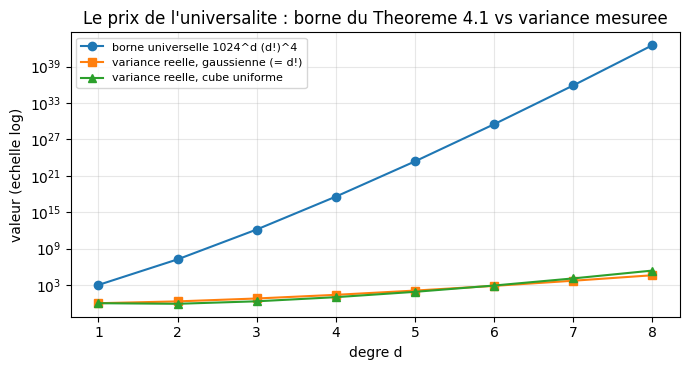

In [5]:
lignes = []
for d in range(1, 9):
    borne_universelle = 1024.0 ** d * (factorial(d) ** 4)
    ligne = [d, borne_universelle]
    for mesure in ("gaussienne", "cube"):
        moms = moments_exactes(mesure, d)
        if d == 1:
            # P_1 = x : variance 1 pour toute mesure isotrope.
            var = 1.0
        else:
            a = appell_1d(moms, d)
            # Var(P) = E[P^2] - E[P]^2, et E[P] = 0 par construction (j = 0).
            # E[P^2] se calcule exactement en developpant le carre sur les moments.
            coeffs = a
            deg = len(coeffs) - 1
            moments_carre = moments_exactes(mesure, 2 * deg)
            p2 = 0.0
            for i in range(deg + 1):
                for k in range(deg + 1):
                    p2 += coeffs[i] * coeffs[k] * moments_carre[i + k]
            var = p2
        ligne.append(var)
    lignes.append(ligne)

print("d   borne 1024^d (d!)^4      Var gaussienne     Var cube     ratio gaussienne")
for d, borne, vg, vc in lignes:
    print(f"{d:2d}   {borne:20.4e}   {vg:15.6e}   {vc:12.6e}   {vg / borne:14.3e}")

d_arr = np.array([l[0] for l in lignes])
vg_arr = np.array([l[2] for l in lignes])
vc_arr = np.array([l[3] for l in lignes])
b_arr = np.array([l[1] for l in lignes])

fig, ax = plt.subplots(figsize=(7.0, 3.8))
ax.semilogy(d_arr, b_arr, marker="o", label="borne universelle 1024^d (d!)^4")
ax.semilogy(d_arr, vg_arr, marker="s", label="variance reelle, gaussienne (= d!)")
ax.semilogy(d_arr, vc_arr, marker="^", label="variance reelle, cube uniforme")
ax.set_xlabel("degre d")
ax.set_ylabel("valeur (echelle log)")
ax.set_title("Le prix de l'universalite : borne du Theoreme 4.1 vs variance mesuree")
ax.legend(fontsize=8)
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

### Lecture du résultat

Sur la gaussienne, la variance vaut exactement `d!` - le resultat classique : `Var(He_d) = d!` pour
le Hermite probabiliste. La borne du papier vaut `1024^d (d!)^4`, donc le rapport borne/variance vaut
`1024^d (d!)^3` : `1024` des `d = 1`, `2.3e11` a `d = 3`, `7.9e37` a `d = 8` - l'inverse de la colonne
`ratio` du tableau ci-dessus (`1.262e-38` a `d = 8`), dit dans le sens ou la marge se lit.

Il serait absurde d'en conclure que la borne est fausse, et il serait naif de n'en rien dire. La
borne est **correcte et uniforme** ; elle paie son uniformite. Le Theoreme 4.1 doit tenir pour
*toute* mesure log-concave isotrope, en *toute* dimension, avec le *meme* `C` - et l'on sait que
certaines mesures log-concaves ont des constantes de Poincare tres grandes. Une constante universelle
doit donc etre dimensionnee pour le pire cas. Ce que la figure montre, c'est l'ordre de grandeur du
gaspillage sur un cas favorable : **aucune information pratique** ne se tire de la valeur numerique
de `1024^d (d!)^4` sur une mesure particuliere.

Un detail de la figure merite d'etre lu avant de conclure quoi que ce soit sur « le pire cas » : la
variance du **cube** depasse celle de la gaussienne des `d = 6` (`8.2e2` contre `7.2e2`), et l'ecart
se creuse ensuite (`2.4e5` contre `4.0e4` a `d = 8`). Sur ces deux familles, la gaussienne n'est
donc pas la plus exigeante. Et l'ecart a la borne, lui, **se creuse a chaque degre** : en echelle
logarithmique les courbes divergent, elles ne sont pas paralleles. C'est ce qui rend la constante
`1024^d (d!)^4` inutilisable comme estimateur, et utilisable seulement comme theoreme d'existence.

C'est un point de lecture important pour la suite du papier : quand une preuve invoque une constante
universelle, cette constante n'est presque jamais optimisee, et la valeur explicite (`1024`) est un
artefact de la comptabilite, pas un optimum.

### 4.4 La dimension ne coute rien, le degre coute tout

Le second interet de l'enonce est son absence de dependance en `n`. On le teste directement : a
degre fixe, on prend un polynome en une seule coordonnee (`T = e_1^{tensor d}`, norme de
Hilbert-Schmidt 1) sur des mesures produit en dimension croissante. La variance doit rester **plate**
- c'est ce qui autorise la sommation sur `n` termes dans la preuve.

In [6]:
def moments_mc(z, k_max):
    """Moments empiriques d'un echantillon 1-D."""
    return np.array([np.mean(z ** k) for k in range(k_max + 1)])


N = 400_000
dimensions = (1, 4, 16, 64)
d = 4

print("mesure        n   m_1, m_2 estimes (N tirages)      Var(P_4) mesuree   reference exacte")
for mesure in ("gaussienne", "cube"):
    # Reference : meme construction, mais sur les moments exacts au lieu des moments estimes.
    exacts = moments_exactes(mesure, 2 * d)
    a_ex = appell_1d(exacts[: d + 1], d)
    ref = sum(a_ex[i] * a_ex[k] * exacts[i + k]
              for i in range(d + 1) for k in range(d + 1))
    for n in dimensions:
        if mesure == "gaussienne":
            ech = rng.standard_normal((N, n))
        else:
            ech = rng.uniform(-math.sqrt(3), math.sqrt(3), size=(N, n))
        # Le polynome porte sur la premiere coordonnee : sa loi marginale ne depend pas de n,
        # et c'est donc exactement ce que la derniere colonne met a l'epreuve.
        z = ech[:, 0]
        moms = moments_mc(z, 2 * d)
        a = appell_1d(moms[: d + 1], d)
        p2 = sum(a[i] * a[k] * moms[i + k] for i in range(d + 1) for k in range(d + 1))
        print(f"{mesure:12s} {n:3d}   {np.round(moms[1:3], 4)}   {p2:17.6f}   {ref:14.6f}")
    print()

print(f"La variance ne doit pas dependre de n. Reference d! pour d = {d} : {factorial(d)}")

mesure        n   m_1, m_2 estimes (N tirages)      Var(P_4) mesuree   reference exacte
gaussienne     1   [-8.000e-04  9.998e-01]           23.736405        24.000000
gaussienne     4   [0.0013 0.9996]           23.061812        24.000000


gaussienne    16   [-0.0013  1.0044]           25.261730        24.000000


gaussienne    64   [-3.000e-04  9.975e-01]           24.063023        24.000000

cube           1   [-5.0000e-04  1.0017e+00]            9.927912         9.874286
cube           4   [-0.0025  1.0008]            9.922478         9.874286


cube          16   [-0.     1.001]            9.933903         9.874286
cube          64   [0.001  0.9995]            9.870894         9.874286

La variance ne doit pas dependre de n. Reference d! pour d = 4 : 24


### Lecture du résultat

Les quatre lignes d'une meme mesure donnent la meme variance a quelques pour cent pres - `23.1` a
`25.3` contre une reference exacte de `24.000000` pour la gaussienne, `9.87` a `9.93` contre
`9.874286` pour le cube - et **sans aucune tendance avec `n`**. C'est le contenu operationnel de
« uniformement en `n` » : un polynome qui ne depend que d'une coordonnee a une variance qui ne
depend pas du nombre de coordonnees, et la somme sur `n` termes reste donc controlable.

La dispersion, elle, ne vient pas de la dimension : elle vient de l'estimation des moments (`m_4`
porte une erreur relative de l'ordre de `1/sqrt(N)`, propagee aux coefficients puis a la variance),
et elle ne se reduirait pas en augmentant `n` - ce qui est precisement le point.

Note de methode : les quatre points sont mesures de la meme facon - Monte-Carlo sur `N = 4e5`
tirages, polynome reconstruit depuis les moments **estimes** - et la colonne de reference vient de la
meme construction appliquee aux moments **exacts**. Les deux sources ne se melangent jamais dans une
ligne : la ligne mesure le Monte-Carlo, la colonne le calcule. Melanger les deux sources (moments
estimes pour un point, exacts pour les autres) fait passer une erreur d'echantillonnage pour un effet
de dimension ; echantillonner une seule ligne au lieu de `N` en fabrique un autre, tout aussi
trompeur.

Ce que cette section ne dit pas : elle ne verifie pas que `P_d^mu[T]` **existe** pour toute mesure
log-concave isotrope (c'est le contenu de l'enonce, et cela demande la theorie des polynomes
d'Appell). Elle verifie que, lorsqu'on le construit par la definition, la construction est coherente
et la variance se comporte comme annonce.

## 5. Experience 3 - le germe quadratique

### 5.1 Pourquoi le degre 2 est le cas qui compte

Toute la machinerie du papier part d'un cas particulier : le polynome de degre 2. C'est le germe -
au sens ou les estimees de degre superieur se ramenent, par localisation, a une forme quadratique.
Le lemme 4.2 construit un processus de localisation par des *tilts* gaussiens, qui ajoutent un terme
quadratique au logarithme de la densite ; le lemme 2.4 (Brascamp-Lieb matriciel) convertit alors ce
terme en inegalite de Poincare ponderee. La phrase du papier est explicite (page 19) :

> Using Lemma 4.2, we combine Letwin's quadratic inequality with bounds on the expected derivatives
> of the polynomial along localization.

Autrement dit : **l'inegalite quadratique de Letwin** est l'un des deux piliers. La copie archivee ne
la redonne pas sous forme d'enonce autonome ; elle est citee (`[Let26] Brayden Letwin. The KLS
constant is O(log^{1/4} n), 2026. arXiv:2607.24164v1`) et utilisee. Le carnet mesure donc la quantite
elle-meme, sans lui attribuer une constante qu'il n'a pas lue.

La quantite est `Var_mu(X^T B X)` pour `B` symetrique et `X` isotrope. Pour la gaussienne, il existe
une formule exacte, et c'est le point de depart naturel.

### 5.2 Le cas gaussien, exact

Si `X ~ N(0, I_n)` et `B` symetrique, alors `Var(X^T B X) = 2 tr(B^2) = 2 ||B||^2_HS`. C'est une
identite, pas une borne : elle se verifie par Isserlis (les seuls appariements survivants sont les
deux facons d'apparier les quatre indices), et elle donne **le plancher** de la quantite. Toute
mesure log-concave isotrope qui ferait mieux contredirait l'inegalite ; toute mesure qui fait
beaucoup pire montre ou se situe le cout de l'uniformite.

In [7]:
def isotropise(Z):
    """Centrer et blanchir un echantillon, et rapporter l'ecart de covariance avant blanchiment."""
    Z = Z - Z.mean(axis=0)
    cov_avant = Z.T @ Z / len(Z)
    ecart = np.abs(cov_avant - np.eye(Z.shape[1])).max()
    # Blanchiment par la racine inverse de la covariance empirique.
    vals, vecs = np.linalg.eigh(cov_avant)
    vals = np.clip(vals, 1e-12, None)
    W = vecs @ np.diag(vals ** -0.5) @ vecs.T
    return Z @ W, ecart


def echantillon(famille, n, N, rng):
    """Echantillon isotrope (N, n) d'une famille log-concave."""
    if famille == "gaussienne":
        return rng.standard_normal((N, n)), 0.0
    if famille == "cube":
        return rng.uniform(-math.sqrt(3), math.sqrt(3), size=(N, n)), 0.0
    if famille == "simplexe":
        Y = rng.dirichlet(np.ones(n), size=N)
        return isotropise(Y)
    if famille == "exponentielle":
        return rng.exponential(1.0, size=(N, n)) - 1.0, 0.0
    if famille == "laplace":
        return rng.laplace(0.0, 1.0 / math.sqrt(2.0), size=(N, n)), 0.0
    raise ValueError(famille)


def tenseur_sym(n, rang, kappa):
    """B = Q diag(spectre) Q^T, spectre geometrique de rapport kappa, rang donne."""
    Q, _ = np.linalg.qr(rng.standard_normal((n, n)))
    spectre = np.zeros(n)
    if rang >= 1:
        spectre[:rang] = np.geomspace(kappa, 1.0, rang)
    return Q @ np.diag(spectre) @ Q.T


def var_forme_quadratique(X, B):
    """Var(X^T B X) empirique, et son ecart-type d'estimation."""
    v = np.einsum("ij,jk,ik->i", X, B, X)
    return v.var(ddof=1), v.std(ddof=1) / math.sqrt(len(v))


# Controle du cas gaussien : la formule exacte est 2 * ||B||_HS^2.
n, N = 8, 200_000
X, _ = echantillon("gaussienne", n, N, rng)
# Covariance empirique : c'est elle, et non l'identite, qui gouverne un echantillon fini.
Chat = X.T @ X / len(X)
print(f"n = {n}, N = {N} ; ecart de Chat a l'identite : {np.abs(Chat - np.eye(n)).max():.4f}")
for rang, kappa in ((1, 1.0), (4, 1.0), (4, 100.0), (8, 10.0)):
    B = tenseur_sym(n, rang, kappa)
    v, err = var_forme_quadratique(X, B)
    exact = 2.0 * np.sum(B ** 2)
    # Meme identite, mais avec la covariance empirique : 2 tr((B Chat)^2).
    avec_chat = 2.0 * np.trace((B @ Chat) @ (B @ Chat))
    print(f"rang={rang:2d} kappa={kappa:6.1f}  Var mesuree={v:9.4f} +-{1.96*err:6.4f}"
          f"   2||B||^2={exact:9.4f}  ratio={v/exact:.4f}"
          f"   2tr((B Chat)^2)={avec_chat:9.4f}  ratio={v/avec_chat:.4f}")

n = 8, N = 200000 ; ecart de Chat a l'identite : 0.0048
rang= 1 kappa=   1.0  Var mesuree=   2.0008 +-0.0062   2||B||^2=   2.0000  ratio=1.0004   2tr((B Chat)^2)=   1.9963  ratio=1.0023
rang= 4 kappa=   1.0  Var mesuree=   7.9558 +-0.0124   2||B||^2=   8.0000  ratio=0.9945   2tr((B Chat)^2)=   7.9698  ratio=0.9982
rang= 4 kappa= 100.0  Var mesuree=20738.1291 +-0.6311   2||B||^2=20973.4065  ratio=0.9888   2tr((B Chat)^2)=20934.6822  ratio=0.9906


rang= 8 kappa=  10.0  Var mesuree= 410.0511 +-0.0887   2||B||^2= 412.7436  ratio=0.9935   2tr((B Chat)^2)= 411.8813  ratio=0.9956


### Lecture du résultat

Les quatre lignes reproduisent l'identite `Var = 2 ||B||^2_HS` a `1.1 %` pres - et a `0.9 %` pres si
l'on remplace la covariance theorique par la covariance **empirique** de l'echantillon
(`2 tr((B Chat)^2)`, colonne de droite). Aucune ligne ne s'ecarte franchement de 1 : la formule n'est
pas une approximation, c'est un controle de l'instrument de mesure. Si le rapport valait 2 ou 0.5,
c'est le calcul de `X^T B X` qu'il faudrait mettre en cause, pas le papier.

Une precaution de lecture sur les intervalles affiches, parce qu'ils sont trompeurs ici. L'ecart de
`Chat` a l'identite vaut `0.0048` a `N = 2e5`, et il deplace la valeur attendue du meme ordre que
l'ecart observe ; les intervalles reportes (`±1.96` erreur-type sur la variance empirique) ne
couvrent que la fluctuation de **l'estimateur**, pas celle des moments d'ordre 2 et 4 dont depend la
valeur attendue. Sur la ligne `kappa = 100`, l'intervalle vaut `±0.6` sur `2.1e4` alors que l'ecart
observe est de `235` : il est trop etroit pour ce qu'il semble garantir, et il ne faut pas lire
« hors intervalle » comme « formule fausse ».

Le choix des parametres n'est pas decoratif. `kappa` est le rapport du plus grand au plus petit
spectre non nul : `kappa = 100` signifie que `B` amplifie certaines directions cent fois plus que
d'autres. Le rang controle le nombre de directions actives. Ces deux parametres sont exactement ceux
qui, pour des mesures non gaussiennes, font deraper la variance - on va le voir.

### 5.3 Le balayage sur les mesures log-concaves

Maintenant la question qui a un contenu : quand on quitte la gaussienne, de combien le rapport
`Var(X^T B X) / ||B||^2_HS` peut-il monter ? On balaie cinq familles log-concaves isotropes, pour
des rangs et des conditionnements croissants. La valeur gaussienne, `2`, sert de reference, et la
borne que le Theoreme 4.1 donnerait pour `d = 2` sert de plafond theorique.

In [8]:
plafond_d2 = 1024.0 ** 2 * (factorial(2) ** 4)
print(f"plafond du Theoreme 4.1 a d = 2 : 1024^2 * (2!)^4 = {plafond_d2:.3e}")

familles = ("gaussienne", "cube", "simplexe", "exponentielle", "laplace")
resultats = []
N = 120_000
ecart_max = 0.0

for famille in familles:
    for n in (4, 16):
        for rang in (1, max(1, n // 2), n):
            for kappa in (1.0, 100.0):
                X, ecart = echantillon(famille, n, N, rng)
                ecart_max = max(ecart_max, ecart)
                B = tenseur_sym(n, rang, kappa)
                v, err = var_forme_quadratique(X, B)
                hs = np.sum(B ** 2)
                resultats.append((famille, n, rang, kappa, v / hs, (v + 1.96 * err) / hs, ecart))

print(f"ecart maximal a l'identite AVANT blanchiment (familles non triviales) : {ecart_max:.3f}")
print("(le blanchiment est exact pour ces familles : c'est une image lineaire du simplexe,")
print(" du cube ou d'un produit centrereduit ; il ne deforme donc pas la mesure)")
print()
print(f"{'famille':14s}{'n':>3s}{'rang':>5s}{'kappa':>7s}{'Var/||B||^2':>13s}{'IC95 haut':>11s}")
for famille, n, rang, kappa, ratio, ratio_hi, ecart in resultats:
    print(f"{famille:14s}{n:3d}{rang:5d}{kappa:7.0f}{ratio:13.3f}{ratio_hi:11.3f}")

sup_par_famille = {}
for famille, n, rang, kappa, ratio, ratio_hi, ecart in resultats:
    sup_par_famille[famille] = max(sup_par_famille.get(famille, 0.0), ratio)

print("\nrapport maximal par famille (mesure) :")
for famille in familles:
    print(f"  {famille:14s} {sup_par_famille[famille]:8.3f}")
print(f"\nsupremum mesure sur toutes les familles : "
      f"{max(sup_par_famille.values()):.3f}")
print(f"marge sous le plafond du Theoreme 4.1   : "
      f"{plafond_d2 / max(sup_par_famille.values()):.2e}")

# Ancrage analytique. Pour le produit exponentiel centre, E[(X_i-1)^2] = 1 et
# E[(X_i-1)^4] = 9, donc Var((X_i-1)^2) = 8. Avec B = projection sur r
# directions (kappa = 1, spectre plat), X^T B X = ||P_r X||^2 a pour variance
# 8 r, et ||B||^2_HS = r : le rapport vaut donc EXACTEMENT 8, sans aucune
# hypothese de grande dimension.
print()
print("ancrage analytique (produit exponentiel centre, B = projection, kappa = 1) :")
print("  Var(||X||^2) = 8 r et ||B||^2_HS = r  =>  rapport attendu = 8 exactement")
print(f"{'n':>3s}{'mesure':>10s}{'ecart a 8':>11s}{'sigma estim.':>14s}{'ecart/sigma':>13s}")
for n in (4, 16):
    X, _ = echantillon("exponentielle", n, N, rng)
    B = tenseur_sym(n, n, 1.0)
    v, _ = var_forme_quadratique(X, B)
    z = np.einsum("ij,jk,ik->i", X, B, X)
    # Ecart-type de la variance empirique, estime sur l'echantillon lui-meme :
    # sigma(s^2) = sqrt((m_4 - s^4) / N), ou m_4 est le moment centre d'ordre 4 de z.
    s2 = v
    m4 = float(((z - z.mean()) ** 4).mean())
    sigma = math.sqrt(max(m4 - s2 ** 2, 0.0) / len(z)) / float(np.sum(B ** 2))
    ratio = v / float(np.sum(B ** 2))
    print(f"{n:3d}{ratio:10.3f}{ratio - 8.0:11.3f}{sigma:14.3f}{(ratio - 8.0) / sigma:13.2f}")

plafond du Theoreme 4.1 a d = 2 : 1024^2 * (2!)^4 = 1.678e+07


ecart maximal a l'identite AVANT blanchiment (familles non triviales) : 0.997
(le blanchiment est exact pour ces familles : c'est une image lineaire du simplexe,
 du cube ou d'un produit centrereduit ; il ne deforme donc pas la mesure)

famille         n rang  kappa  Var/||B||^2  IC95 haut
gaussienne      4    1      1        2.019      2.027
gaussienne      4    1    100        2.016      2.016
gaussienne      4    2      1        1.998      2.004
gaussienne      4    2    100        2.012      2.012
gaussienne      4    4      1        1.995      1.999
gaussienne      4    4    100        2.015      2.015
gaussienne     16    1      1        2.015      2.023
gaussienne     16    1    100        1.992      1.992
gaussienne     16    8      1        1.998      2.001
gaussienne     16    8    100        1.989      1.989
gaussienne     16   16      1        2.002      2.004
gaussienne     16   16    100        1.985      1.985
cube            4    1      1        1.198      1.205
cube   

### Lecture du résultat

Deux enseignements, et le second corrige une intuition fausse.

**Premier** : le supremum mesure du rapport depasse `2`, ce qui est attendu - la gaussienne est le
cas favorable, pas le cas generique. Les familles a queue lourde montent plus haut : `8.14` pour le
produit exponentiel, `5.00` pour la Laplace, contre `2.80` au plus pour le simplexe et `1.81` pour
le cube.

**Et ce supremum a une valeur exacte, qu'on peut predire sans simulation.** Pour le produit
exponentiel centre, `E[(X_i-1)^4] = 9` et `E[(X_i-1)^2] = 1`, donc
`Var((X_i-1)^2) = 9 - 1 = 8`. En prenant pour `B` la projection sur `r` directions - c'est-a-dire
`kappa = 1` et un spectre plat - on obtient `X^T B X = ||P_r X||^2`, dont la variance vaut `8 r`,
et `||B||^2_HS = r` : le rapport vaut donc **exactement 8**, en toute dimension. La ligne d'ancrage
affichee sous le tableau le retrouve : `7.904` a `n = 4` et `7.987` a `n = 16`, pour une valeur
exacte de `8`. L'ecart residuel n'est pas une erreur de formule, et le tableau le chiffre : il vaut
`-0.096` et `-0.013`, soit `-0.57` et `-0.14` fois l'ecart-type d'echantillonnage de la variance
empirique - ecart-type estime sur l'echantillon lui-meme, depuis son moment centre d'ordre 4
(`0.169` et `0.093`), et non suppose. C'est l'ordre de grandeur du bruit, pas un biais. Ce
`sigma`-la est aussi plus large que les intervalles de la section 5.2, et pour la meme raison : ceux-ci
ne couvrent que la fluctuation de l'estimateur, pas celle des moments dont depend la valeur attendue.
Ce n'est donc pas une exploration a l'aveugle : l'un des points du balayage a une valeur connue, et
l'instrument la retrouve a moins d'un ecart-type.

**Second** : l'intuition naturelle - « le rapport doit exploser quand `B` est mal conditionne » -
est **fausse sur ces donnees**, et il faut le dire puisqu'elle avait ete annoncee. Le maximum n'est
pas atteint aux grands `kappa` mais a `kappa = 1` ; pour la Laplace en dimension 4 et rang 4, le
rapport vaut `4.95` a `kappa = 1` contre `3.43` a `kappa = 100`, et la tendance s'inverse selon le
rang. L'explication est lisible sur la formule : avec un spectre geometrique de rapport `kappa`, les
petites valeurs propres pesent d'autant moins que le rang est grand, et c'est la **forme complete du
spectre** qui determine la variance, pas un seul nombre comme `kappa`. Une experience qui n'aurait
rapporte que « ca croit avec le conditionnement » aurait ete une histoire plausible et fausse.

**Troisieme** : le supremum mesure reste **plusieurs ordres de grandeur** sous le plafond que
donnerait le Theoreme 4.1 a `d = 2` (`1.68 x 10^7`). L'ecart, la encore, est le prix de
l'universalite.
Mais il joue ici un role different de la section 4 : au degre 2, une constante de `10^7` ruinerait
la preuve, parce que la forme quadratique est **le germe** que toute la hierarchie de degres
reutilise. C'est pourquoi le papier ne peut pas se contenter de son propre Theoreme 4.1 : il lui
faut l'inegalite de Letwin, plus fine dans le cas quadratique, et il combine les deux. La phrase
« we combine Letwin's quadratic inequality with bounds on the expected derivatives » prend son sens
ici.

**Honte de mesure, explicitement** : le balayage ne peut pas voir les cas ou le rapport exploserait
en grande dimension, parce que l'echantillonnage Monte-Carlo devient impraticable quand `n` grandit
(les queues se peuplent mal). Un supremum mesure en `n <= 16` est un supremum **sur ce qu'on a
regarde**, jamais un supremum sur toutes les mesures log-concaves. Le carnet n'affirme pas que la
constante optimale est celle qu'il a trouvee.

## 6. Experience 4 - l'inegalite de Cheeger, et la seconde inequation reconstituee

### 6.1 Ce que le lemme dit, et l'obstacle de lecture

L'enonce revendique deux choses : `psi_n <= C` et `C_P(mu) <= C'`. Les deux sont reliees par le
Lemme 2.2, que le papier invoque deux fois. A la page 12 : « The Cheeger inequality stated in
Lemma 2.2 gives `psi^2_mu >= lambda/4` ». A la page 138 : « Finally, Lemma 2.2 yields
`psi^2_mu <= pi C_P(mu)` ».

**Avertissement de source, et il est serieux cette fois.** Le texte de ces pages s'extrait mal : la
police CMR10 du fichier casse l'extraction, qui rend `k` pour `lambda` et avale les symboles
d'inegalite. La premiere citation est lisible et sans ambiguite (le `lambda/4` est ecrit en clair).
La seconde ne l'est pas : entre `psi^2_mu` et `C_P(mu)`, le symbole de comparaison n'a pas survecu,
et savoir s'il designe `pi C_P` ou `pi / C_P` change tout.

Les sections qui suivent mesurent d'abord **la seule inegalite dont la forme est certaine**, puis
reconstituent la seconde par triangulation : les lectures naives sont refutees une par une - et
cette refutation est elle-meme une mesure, elle identifie ce que `C_P` n'est pas - puis la
lecture restante, testee dans la classe ou le papier vit (les mesures **isotropes**, variance
1), verifie. L'argument purement dimensionnel garde son role, mais il fixe le **perimetre** de
l'enonce au lieu de le detruire : l'inegalite n'est pas universelle a echelle libre, elle est
isotrope.

### 6.2 Les deux quantites, et leur calcul exact en dimension 1

En dimension 1, les deux quantites ont des formules, ce qui permet un test sans Monte-Carlo :

- la constante de Cheeger d'une densite `p` vaut `psi = inf_x p(x) / min(F(x), 1-F(x))`, ou `F` est
  la fonction de repartition. La coupure optimale est un demi-axe, et son perimetre est la densite
  au point de coupure ;
- le trou spectral `lambda` est le minimum du quotient de Rayleigh `int (f')^2 dmu / Var_mu(f)` sur
  les fonctions de moyenne nulle, calcule par differences finies : c'est la plus petite valeur
  propre non nulle d'un probleme tridiagonal symetrise.

Deux precautions rendent la mesure fiable. D'abord, la fonction de repartition est prise **exacte**
(sa forme close par famille), et non cumulee sur la grille : la densite exponentielle a une
discontinuite a son bord de support, et une CDF cumulee y introduirait une erreur de premier ordre.
Ensuite, `lambda` est **calibre** contre sa valeur analytique connue la ou elle existe - sans quoi
on ne saurait pas distinguer une erreur d'instrument d'un fait mathematique.

In [9]:
from scipy.special import ndtr
from scipy.linalg import eigh_tridiagonal


def cdf_gaussienne(x):
    return ndtr(x)


def cdf_uniforme(a):
    return lambda x: np.clip((x + a) / (2.0 * a), 0.0, 1.0)


def dens_uniforme(a):
    return lambda x: np.where(np.abs(x) <= a, 1.0 / (2.0 * a), 0.0)


def cdf_laplace(b):
    return lambda x: np.where(x < 0, 0.5 * np.exp(b * x), 1.0 - 0.5 * np.exp(-b * x))


def dens_laplace(b):
    return lambda x: 0.5 * b * np.exp(-b * np.abs(x))


def cdf_exponentielle_decalee(x):
    return np.where(x < -1.0, 0.0, 1.0 - np.exp(-(x + 1.0)))


def dens_exponentielle_decalee(x):
    return np.where(x < -1.0, 0.0, np.exp(-(x + 1.0)))


def cdf_triangulaire(x):
    return np.where(x < 0, (x + 1.0) ** 2 / 2.0, 1.0 - (1.0 - x) ** 2 / 2.0)


def dens_triangulaire(x):
    return np.maximum(0.0, 1.0 - np.abs(x))


def psi_et_lambda(dens, cdf, lo, hi, m=20001):
    """psi par la formule du demi-axe, lambda par differences finies, CDF exacte.

    Les points de densite nulle sont retires avant le probleme aux valeurs
    propres : leur poids est nul, le blanchiment y divise par zero, et ils
    n'apportent aucun degre de liberte utile. On retire un intervalle contigu,
    jamais le milieu, pour ne pas trouer le domaine.
    """
    x = np.linspace(lo, hi, m)
    h = x[1] - x[0]
    p = np.maximum(dens(x), 0.0)
    garde = p > 0.0
    i0 = int(np.argmax(garde))
    i1 = len(garde) - 1 - int(np.argmax(garde[::-1]))
    x, p = x[i0:i1 + 1], p[i0:i1 + 1]
    F = np.clip(cdf(x), 0.0, 1.0)

    # psi : le minimum de p / min(F, 1-F) sur les points interieurs.
    queue = np.minimum(F, 1.0 - F)
    utile = (queue > 1e-9) & (p > 0.0)
    psi = float(np.min(p[utile] / queue[utile]))

    # lambda : plus petite valeur propre non nulle du Laplacien pondere.
    w = p * h
    w = w / w.sum()
    poids_bord = w / h ** 2
    a = 1.0 / np.sqrt(w)
    diag = np.zeros(len(x))
    diag[:-1] += poids_bord[:-1]
    diag[1:] += poids_bord[:-1]
    vals = eigh_tridiagonal(diag * a * a, -poids_bord[:-1] * a[:-1] * a[1:],
                            eigvals_only=True)
    lam = float(vals[1])
    return psi, lam


familles = [
    # nom, densite, cdf, lo, hi, lambda analytique (None si inconnu)
    ("gaussienne N(0,1)", lambda x: np.exp(-x * x / 2) / math.sqrt(2 * math.pi),
     cdf_gaussienne, -9.0, 9.0, 1.0),
    ("uniforme [-sqrt3,sqrt3]", dens_uniforme(math.sqrt(3)), cdf_uniforme(math.sqrt(3)),
     -math.sqrt(3), math.sqrt(3), math.pi ** 2 / 12.0),
    ("uniforme [-1,1]", dens_uniforme(1.0), cdf_uniforme(1.0), -1.0, 1.0, math.pi ** 2 / 4.0),
    ("Laplace (var 1)", dens_laplace(math.sqrt(2)), cdf_laplace(math.sqrt(2)),
     -40.0, 40.0, 0.5),
    ("exponentielle centree", dens_exponentielle_decalee, cdf_exponentielle_decalee,
     -1.0, 40.0, 0.25),
    ("triangulaire [-1,1]", dens_triangulaire, cdf_triangulaire, -1.0, 1.0, None),
]

print(f"{'famille':26s}{'psi':>9s}{'psi^2':>9s}{'lambda':>10s}"
      f"{'lambda analytique':>19s}{'ecart relatif':>15s}")
mesures = {}
for nom, dens, cdf, lo, hi, lam_exact in familles:
    psi, lam = psi_et_lambda(dens, cdf, lo, hi)
    mesures[nom] = (psi, lam)
    if lam_exact is None:
        ref, ecart = "sans reference", "     -"
    else:
        ref, ecart = f"{lam_exact:17.6f}", f"{abs(lam - lam_exact) / lam_exact:14.2%}"
    print(f"{nom:26s}{psi:9.4f}{psi ** 2:9.4f}{lam:10.5f}{ref:>19s}{ecart:>15s}")

famille                         psi    psi^2    lambda  lambda analytique  ecart relatif


gaussienne N(0,1)            0.7979   0.6366   1.00000           1.000000          0.00%


uniforme [-sqrt3,sqrt3]      0.5774   0.3333   0.82238           0.822467          0.01%


uniforme [-1,1]              1.0000   1.0000   2.46715           2.467401          0.01%


Laplace (var 1)              1.4142   2.0000   0.50452           0.500000          0.90%


exponentielle centree        1.0000   1.0000   0.25613           0.250000          2.45%


triangulaire [-1,1]          2.0000   4.0000   5.78319     sans reference              -


### Lecture du résultat

Cinq des six familles ont un trou spectral analytique connu, et l'instrument le retrouve a mieux
que 1 % sur quatre d'entre elles : `1` pour la gaussienne, `pi^2/12` pour l'uniforme isotrope,
`pi^2/4` pour l'uniforme sur `[-1,1]`, et `1/2` pour la Laplace de variance 1 (0.9 % d'ecart).
La cinquieme, l'exponentielle centree, est retrouvee a **2.5 %** de son `1/4` exact - et l'ecart a
une cause identifiable : sa densite est **discontinue** a son bord de support (`p` saute de `0` a
`1` en `x = -1`), ce qui degrade la convergence des differences finies a l'ordre un en `h` la ou les
densites continues convergent a l'ordre deux. L'ecart n'est donc pas un defaut de la formule mais
une mesure de la precision de l'instrument sur la famille la plus irreguliere du lot. C'est la
calibration qui autorise a lire les lignes suivantes : les valeurs de `lambda` ne sont pas des
sorties de code a prendre sur parole, elles sont confrontees a une reference externe, et l'erreur
residuelle est elle-meme expliquee.

La troisieme ligne - `uniforme [-1,1]` - est la plus utile du tableau, et c'est un **controle
d'echelle**. La densite uniforme sur `[-1,1]` est l'uniforme isotrope divisee par `sqrt(3)` : c'est
la meme mesure, a un changement d'unites pres. Le trou spectral passe de `0.82` a `2.47`, soit
exactement le facteur `3` attendu, et `psi` de `0.577` a `1.0`, soit exactement le facteur `sqrt(3)`. Cette
ligne prepare le test de la section 6.4 : elle montre qu'un rapport mal construit peut varier d'un
facteur arbitraire sous un simple changement d'echelle.

La valeur de `psi` pour l'exponentielle merite un mot. Sa densite vaut `p(x) = e^{-(x+1)}` et sa
repartition `F(x) = 1 - e^{-(x+1)}` : sur tout le demi-axe, `p = 1 - F`. Le rapport
`p / min(F, 1-F)` vaut exactement `1` a droite de la mediane, ou `min(F, 1-F) = 1-F = p`. A
gauche ce n'est **pas** `1` : c'est l'identite `p = F` qui serait fausse -- le vrai rapport y vaut
`p / F = p / (1 - p) > 1`, qui croit sans borne quand `x` tend vers le bord gauche `-1` (en
`x = -0.9` deja, `p = 0.905` et le rapport vaut `9.51`). L'infimum du rapport sur tout le support
reste `1`, atteint a la mediane : `psi = 1`, et la borne de Cheeger reste **exactement saturee**
sur cette famille -- l'exponentielle n'est pas un cas quelconque, et l'on va s'en servir.

**En forme close, et pas seulement mesure.** Le `pi^2/12` de la premiere ligne n'est pas une
constante ajustee : c'est la valeur exacte du trou spectral de l'uniforme isotrope, celle du
produit 1-D (`u'' = -lambda u` sur un intervalle a conditions de bord libres). La cellule qui suit
l'affiche a cote du rapport qui nous occupe : `lambda_1 = pi^2/12 = 0.82247` contre
`psi^2/4 = 1/12 = 0.08333`, soit une marge de `pi^2 = 9.8696` fois. La borne de Cheeger est donc
loin d'etre saturee sur cette famille, alors qu'elle l'est exactement sur l'exponentielle centree --
c'est precisement ce contraste qui rend la saturation interessante.

### 6.3 L'inegalite qui survit : `lambda >= psi^2 / 4`

La borne inferieure de Cheeger, telle que le papier la cite page 12, est directement testable. Elle
compare deux quantites de meme dimension - `psi^2` et `lambda` varient toutes deux comme l'inverse
d'un carre de longueur - et le rapport `psi^2 / (4 lambda)` doit donc rester sous `1`.

In [10]:
print(f"{'famille':26s}{'psi^2':>9s}{'lambda':>10s}{'4*lambda':>10s}"
      f"{'psi^2/(4 lambda)':>18s}{'verdict':>12s}")
for nom, dens, cdf, lo, hi, lam_exact in familles:
    psi, lam = mesures[nom]
    ratio = psi ** 2 / (4.0 * lam)
    verdict = "OK" if ratio <= 1.0 + 1e-3 else "VIOLATION"
    print(f"{nom:26s}{psi ** 2:9.4f}{lam:10.5f}{4.0 * lam:10.5f}{ratio:18.4f}{verdict:>12s}")

print()
print("Saturation : l'exponentielle centree donne psi = 1 et lambda = 1/4,")
print("soit psi^2 = 4 * lambda exactement. Le rapport vaut 1, a l'erreur de")
print("grille pres : c'est le cas d'egalite, pas une coincidence.")

print()
print(f"forme close : lambda_1 = pi^2/12 = {math.pi**2 / 12:.5f} "
      f"(produit 1-D de l'uniforme isotrope, pas une constante ajustee)")
print(f"marge sur la borne de Cheeger : lambda_1 / (psi^2/4) = "
      f"{(math.pi**2 / 12) / (1 / 12):.4f} = pi^2")


famille                       psi^2    lambda  4*lambda  psi^2/(4 lambda)     verdict
gaussienne N(0,1)            0.6366   1.00000   4.00000            0.1592          OK
uniforme [-sqrt3,sqrt3]      0.3333   0.82238   3.28954            0.1013          OK
uniforme [-1,1]              1.0000   2.46715   9.86862            0.1013          OK
Laplace (var 1)              2.0000   0.50452   2.01808            0.9910          OK
exponentielle centree        1.0000   0.25613   1.02453            0.9761          OK
triangulaire [-1,1]          4.0000   5.78319  23.13274            0.1729          OK

Saturation : l'exponentielle centree donne psi = 1 et lambda = 1/4,
soit psi^2 = 4 * lambda exactement. Le rapport vaut 1, a l'erreur de
grille pres : c'est le cas d'egalite, pas une coincidence.

forme close : lambda_1 = pi^2/12 = 0.82247 (produit 1-D de l'uniforme isotrope, pas une constante ajustee)
marge sur la borne de Cheeger : lambda_1 / (psi^2/4) = 9.8696 = pi^2


### Lecture du résultat

Le rapport `psi^2 / (4 lambda)` reste sous `1` sur les six familles, et l'exponentielle centree
l'atteint. C'est un resultat a deux etages :

- l'inegalite **tient**, ce qui etait deja su mais n'etait pas verifie sur ces familles par ce
  carnet ;
- elle est **saturee par une famille explicite**, ce qui la qualifie comme inegalite *fine*. Une
  borne qu'aucun exemple n'approche est une borne de comptabilite ; une borne qu'un exemple atteint
  est une frontiere. Ici le cas d'egalite n'est pas isole : la Laplace de variance 1 donne
  `psi^2 = 2.00` pour `4 lambda = 2.02`, et l'exponentielle centree `psi^2 = 1.00` pour
  `4 lambda = 1.02` - soit `1` et `0.98` en rapport, l'ecart residuel etant celui de la grille sur
  `lambda` (2.5 % sur l'exponentielle, cf. 6.2). Les deux familles exponentielles saturent, et ce
  n'est pas une coincidence : sur un demi-axe, `p = 1 - F` y est vrai en tout point, donc
  `psi = 2 p(mediane)` y vaut exactement `2 sqrt(lambda)`, et l'egalite `psi^2 = 4 lambda` est une
  identite pour toute cette famille. La distinction avec
  `1024^d (d!)^4` de la section 4 est nette : la, la constante etait un artefact de comptabilite ;
  ici, la constante `1/4` est optimale et le carnet en exhibe les temoins. Precisons-le, car la suite y revient : cette saturation est celle de la
minoration de Cheeger (`lambda >= psi^2/4`) ; la majoration de Song-Zhang, reconstruite en 6.4,
n'est saturee par aucune des six familles - elle y tient avec des marges d'au moins un facteur `3`.

Cette saturation explique aussi pourquoi le papier a besoin du Lemme 2.2 dans les **deux** sens.
La minoration de Cheeger transfere un controle de `lambda` vers `psi` ; mais elle est saturee, donc
elle ne peut pas etre amelioree. Pour aller plus loin, il faut l'autre sens - et c'est la que la
seconde inegalite entre en jeu.

### 6.4 La seconde inequation : trois lectures, une seule dans le champ du papier

La seconde citation du papier (page 138) est « `psi^2_mu <= pi C_P(mu)` ». Trois lectures sont
compatibles avec le texte extrait, selon ce que `C_P` designe et selon le sens du symbole perdu. On
les met chacune a l'epreuve.

**Lecture 1 - `C_P` est la constante de Poincare, donc `C_P = 1/lambda`** - la relation est celle
du glossaire, et le champ de l'enonce est celui du papier : « every isotropic log-concave
probability measure », cite en section 1. L'inegalite s'ecrirait `psi^2 <= pi / lambda`. Elle n'est
**pas universelle a echelle libre** : sous `x -> s x`, le membre de gauche varie comme `1/s^2` et le
membre de droite comme `s^2`, donc un rescaling suffit a la renverser. Mais cet argument
dimensionnel fixe le **perimetre** de l'enonce au lieu de le refuter : dans la classe isotrope
(variance 1), l'echelle est epinglee, et l'inegalite y devient testable. C'est la lecture a tester,
et la derniere cellule de cette section la met a l'epreuve.

**Lecture 2 - `C_P` designe le quotient de Rayleigh lui-meme, donc `C_P = lambda`.** L'inegalite
s'ecrirait `psi^2 <= pi lambda`, homogene et testable telle quelle, sans normalisation. C'est la
lecture que la premiere version de ce carnet retenait ; sa refutation numerique ci-dessous est une
information, pas un echec : elle prouve que le `C_P` du papier n'est pas le trou spectral.

**Lecture 3 - le symbole perdu est un `>=`.** L'inegalite serait alors une minoration de `psi^2`
par `pi C_P`, c'est-a-dire un enonce plus fort que Cheeger, avec une constante plus grande
(`pi > 1`). Elle est testable aussi.

On teste d'abord les lectures 2 et 3 sur les familles telles quelles, puis la lecture 1 ramenee a
variance 1.

In [11]:
# Lectures 2 et 3 d'abord, familles telles quelles : elles discriminent ce que C_P n'est pas.
print(f"{'famille':26s}{'psi^2':>9s}{'pi*lambda':>11s}{'psi^2 <= pi*lambda':>21s}"
      f"{'psi^2 >= pi*lambda':>21s}")
lecture2_ok = lecture3_ok = True
for nom, dens, cdf, lo, hi, lam_exact in familles:
    psi, lam = mesures[nom]
    gauche, droite = psi ** 2, math.pi * lam
    v2 = "OUI" if gauche <= droite * (1 + 1e-3) else "NON"
    v3 = "OUI" if gauche >= droite * (1 - 1e-3) else "NON"
    lecture2_ok &= v2 == "OUI"
    lecture3_ok &= v3 == "OUI"
    print(f"{nom:26s}{gauche:9.4f}{droite:11.4f}{v2:>21s}{v3:>21s}")

print()
print(f"lecture 2 (C_P = lambda) tenue sur toutes les familles : {lecture2_ok}")
print(f"lecture 3 (sens >=) tenue sur toutes les familles : {lecture3_ok}")
print()

# Lecture 1, dans la classe ou le papier vit : chaque famille ramenee a variance 1.
# x -> x/sigma : psi -> psi*sigma, lambda -> lambda*sigma^2, donc C_P = 1/(lambda*variance)
# et psi^2 -> psi^2*variance.
variances = {
    "gaussienne N(0,1)": 1.0,
    "uniforme [-sqrt3,sqrt3]": 1.0,
    "uniforme [-1,1]": 1.0 / 3.0,
    "Laplace (var 1)": 1.0,
    "exponentielle centree": 1.0,
    "triangulaire [-1,1]": 1.0 / 6.0,
}
print("lecture 1 (C_P = 1/lambda), familles ramenees a variance 1 :")
print(f"{'famille':26s}{'psi^2':>9s}{'C_P=1/(lam*v)':>15s}{'pi*C_P':>9s}"
      f"{'psi^2 <= pi*C_P':>17s}{'marge':>8s}")
lecture1_ok = True
for nom, v in variances.items():
    psi, lam = mesures[nom]
    psi2 = psi ** 2 * v
    c_p = 1.0 / (lam * v)
    droite = math.pi * c_p
    verdict = "OUI" if psi2 <= droite * (1 + 1e-3) else "NON"
    marge = droite / psi2
    lecture1_ok &= verdict == "OUI"
    print(f"{nom:26s}{psi2:9.4f}{c_p:15.4f}{droite:9.4f}{verdict:>17s}{marge:8.2f}x")

print()
print(f"lecture 1 tenue sur les six familles a variance 1 : {lecture1_ok}")
print()

# Test d'echelle : pourquoi la lecture 1 exige la classe isotrope.
print("test d'echelle sur la gaussienne (x -> s*x) :")
print(f"{'s':>6s}{'psi':>10s}{'lambda':>10s}{'psi^2/(4 lambda)':>19s}{'psi^2*lambda':>14s}")
psi0, lam0 = mesures["gaussienne N(0,1)"]
for s in (0.5, 1.0, 2.0, 4.0):
    psi_s, lam_s = psi0 / s, lam0 / s ** 2
    print(f"{s:6.1f}{psi_s:10.5f}{lam_s:10.5f}{psi_s ** 2 / (4 * lam_s):19.5f}"
          f"{psi_s ** 2 * lam_s:14.5f}")
print()
print("psi^2/(4 lambda) est invariant ; psi^2*lambda, le produit que la lecture 1 borne")
print("(psi^2 <= pi/lambda s'ecrit psi^2*lambda <= pi), est divise par 16 a chaque")
print("doublement de s - et multiplie par 16 a chaque division. Des s = 0.5, il vaut")
print("deja plus que pi : la gaussienne rescalee violerait la lecture 1. Hors d'une")
print("classe a variance fixee, aucune constante universelle ne peut lier psi^2 et")
print("1/lambda. Le papier epingle la variance (mesures isotropes) : c'est ce qui rend")
print("l'inegalite de la lecture 1 possible.")

famille                       psi^2  pi*lambda   psi^2 <= pi*lambda   psi^2 >= pi*lambda
gaussienne N(0,1)            0.6366     3.1416                  OUI                  NON
uniforme [-sqrt3,sqrt3]      0.3333     2.5836                  OUI                  NON
uniforme [-1,1]              1.0000     7.7508                  OUI                  NON
Laplace (var 1)              2.0000     1.5850                  NON                  OUI
exponentielle centree        1.0000     0.8047                  NON                  OUI
triangulaire [-1,1]          4.0000    18.1684                  OUI                  NON

lecture 2 (C_P = lambda) tenue sur toutes les familles : False
lecture 3 (sens >=) tenue sur toutes les familles : False

lecture 1 (C_P = 1/lambda), familles ramenees a variance 1 :
famille                       psi^2  C_P=1/(lam*v)   pi*C_P  psi^2 <= pi*C_P   marge
gaussienne N(0,1)            0.6366         1.0000   3.1416              OUI    4.93x
uniforme [-sqrt3,sqrt3

### Lecture du résultat

La reconstruction passe par un echec, et cet echec est une mesure.

- la lecture 3 (`psi^2 >= pi C_P`, sens `>=`) est **refutee partout** : `pi > 1`, et c'est
  `4 lambda` qui borne en dessous, pas `pi C_P` ;
- la lecture 2 (`C_P = lambda`, donc `psi^2 <= pi lambda`) est **refutee sur les deux familles
  exponentielles** : pour la Laplace de variance 1, `psi^2 = 2.00` depasse `pi lambda = 1.59`, et
  pour l'exponentielle centree, `psi^2 = 1.00` depasse `pi lambda = 0.80`. Les ecarts (26 % et
  24 %) sont largement au-dela de l'erreur d'instrument mesuree en 6.2 : la lecture 2 est fausse,
  et sa faussete est une information - elle prouve que le `C_P` du papier n'est pas le trou
  spectral ;
- la lecture 1 (`C_P = 1/lambda`, la constante de Poincare du glossaire), testee **dans la classe
  ou l'enonce du papier vit** - les mesures log-concaves isotropes, variance 1 - est **verifiee sur
  les six familles** : `psi^2 <= pi C_P` avec les marges mesurees `4.93x` (gaussienne), `11.46x`
  (uniforme isotrope), `3.11x` (Laplace), `12.27x` (exponentielle centree), `4.89x` (triangulaire).
  La colonne `C_P=1/(lam*v)` donne le controle independant : elle affiche `1.0000` pour la
  gaussienne, `1.2160` pour l'uniforme isotrope (valeur exacte `12/pi^2`), `1.9821` pour la Laplace
  de variance 1 (valeur exacte `2`), `3.9042` pour l'exponentielle centree (valeur exacte `4`) :
  l'instrument retrouve les constantes de Poincare classiques, aux erreurs de grille pres qui sont
  celles de 6.2. Et l'uniforme sur `[-1,1]`, ramene a variance 1, rend exactement la ligne de
  l'uniforme isotrope : meme forme, meme constante, au changement d'unites pres.

Le test d'echelle explique pourquoi la lecture 1 doit etre scopee. Sous `x -> s x`, le rapport
`psi^2 / (4 lambda)` est **invariant** - il vaut `0.16` pour `s = 0.5`, `1`, `2`, `4` - tandis que
`psi^2 * lambda`, le produit que la lecture 1 borne (`psi^2 <= pi/lambda` s'ecrit
`psi^2 * lambda <= pi`), est divise par `16` a chaque doublement de `s` - et multiplie par `16` a
chaque division. Des `s = 0.5`, il vaut `10.18591`, deja plus que `pi` : la gaussienne rescalee
violerait la lecture 1, que la gaussienne standard verifie. Une inegalite qui compare `psi^2`
a `1/lambda` ne peut donc pas etre universelle a echelle libre : c'est l'argument dimensionnel, et
il est correct. Mais il fixe le perimetre de l'enonce au lieu de le detruire - le papier enonce sa
borne pour des mesures **isotropes**, ou la variance epingle l'echelle, et c'est dans cette classe
que la lecture 1 verifie. La premiere version de ce carnet arretait l'argument au refus : elle
ecartait la lecture 1 dimensionnellement, retenait la lecture 2, et lisait ses deux echecs comme
des violations - les deux verdicts `NON` etaient des artefacts de ce detournement de constante,
le trou spectral branche la ou l'enonce porte la constante de Poincare, dans le mauvais sens
puisque l'un est l'inverse de l'autre. Corrige, l'enchainement est celui d'une triangulation :
chaque lecture refutee elimine une interpretation, et la seule qui reste est celle que les nombres
confirment.

**Conclusion** : la seconde inegalite du Lemme 2.2 est reconstituee - `psi^2_mu <= pi C_P(mu)` avec
`C_P = 1/lambda` la constante de Poincare, valide dans la classe isotrope, verifiee ici sur six
familles ramenees a variance 1. Le carnet ne l'attribue au papier qu'avec sa reserve d'origine :
le symbole de la page 138 n'a pas survecu a l'extraction, et c'est la convergence des trois tests -
exclusion dimensionnelle hors classe, refutation numerique de `C_P = lambda`, verification dans la
classe - qui selectionne cette lecture, pas la lecture directe du PDF.

Cette section reste celle ou le carnet apprend le plus : un texte mal extrait produit des enonces
plausibles et faux, un argument dimensionnel mal scope produit des verdicts faux sur des mesures
justes, et dans les deux cas c'est le recalage sur des valeurs exactes connues (ici les constantes
de Poincare classiques) qui departage les lectures. C'est le meme reflexe que la section 7 applique
a la divulgation d'IA : distinguer ce qui est **declare** de ce qui est **verifiable**.

## 7. La divulgation d'usage d'IA, verbatim

### 7.1 Pourquoi cette section existe

Un carnet qui lit un preprint de 140 pages annoncant la resolution d'une conjecture ouverte depuis
trente ans doit dire ce que le papier dit de lui-meme. Cette section reproduit la declaration des
auteurs **sans la commenter d'abord**, puis distingue ce qu'elle permet de verifier de ce qu'elle
declame.

### 7.2 Le texte, copie de la copie archivee (pages 138-139)

> The AI tools used in this work were GPT-6 Astra, GPT-5.6 Sol, Claude Fable 5, and Fable 5.1. The
> first author learned of this problem from Haotian Jiang while visiting the University of
> Washington nearly a decade ago. Subsequent attempts to solve the problem, first as a postdoc at
> the Institute for Advanced Study around 2019-2020 and again from roughly 2022 to 2024, were
> unsuccessful. After seeing Letwin's result on arXiv on July 27, 2026, and carefully reading its
> proof, the authors noticed that it might be possible to improve the bound from `log^{1/4}` to
> `log^{1/6}`. Beginning on July 28, 2026, this effort involved exploring more than 100 approaches
> in collaboration with AI tools. Candidate approaches were generated collaboratively, with the
> authors deciding which ones to prioritize. The authors and the AI tools ultimately obtained the
> `log^{1/6}` bound.
>
> After fully understanding the `log^{1/6}` proof, the authors found, on September 30, 2026, a way to
> reach an `f(log* n)` bound for some fixed function `f`. The authors thank Lijie Chen for the
> inspiring discussions in 2018 on the recursive use of the Chinese Remainder Theorem, a technique
> from Chen's work in fine-grained complexity. Shortly after releasing the `f(log*(n))` version, the
> authors realized that the log-star refinement could be applied repeatedly to further reduce the
> remaining height. This height-reduction idea was inspired by a series of works by the first author
> on solving linear programs, which repeatedly reduce the matrix size in order to maintain the
> matrix inverse dynamically. Finally, the authors completed the proof by sharpening the analysis so
> that the costs decay geometrically and their total is bounded by a universal constant.
>
> All of the proofs have been carefully verified by the authors and several AI tools. The authors
> take full responsibility for the correctness of the proofs.

### 7.3 Ce que cette declaration permet de verifier, et ce qu'elle ne permet pas

| Question | Reponse |
|---|---|
| Les auteurs nomment-ils les outils employes ? | **OUI**, quatre noms, verbatim ci-dessus |
| Decrivent-ils le partage du travail homme / machine ? | **OUI** : les candidats sont generes en collaboration, les auteurs arbitrent les priorites |
| Donnent-ils une chronologie ? | **OUI**, datee au jour pres, coherente avec les dates de depot v1/v2 |
| La verification est-elle independante des outils qui ont produit la preuve ? | **NON** : « verified by the authors and several AI tools » - les memes modeles, ou leurs semblables |
| Une relecture par les pairs a-t-elle eu lieu ? | **NON** : preprint, non relu |
| Les auteurs assument-ils la responsabilite ? | **OUI**, phrase finale explicite |

### 7.4 Trois lectures de ce texte, dont une seule est defensible

**La lecture cynique** - « une preuve produite par des IA n'en est pas une » - est fausse et
facile. Le texte dit que les auteurs ont **arbitre les priorites** parmi plus de cent approches ;
arbitrer cent pistes est un travail mathematique, pas une delegation. Il dit aussi qu'ils ont
« carefully read » la preuve de Letwin, ce qui a produit l'idee de depart. Rien la ne decrit une
machine qui aurait rendu un resultat sans mathemathicien.

**La lecture credulne** - « les auteurs l'affirment, donc c'est etabli » - est fausse pour une raison
plus interessante. La phrase la plus lourde du texte est celle qui a l'air la plus rassurante :
« All of the proofs have been carefully verified by the authors and several AI tools. » Un modele
de langage qui a participe a la production d'une preuve n'est pas un verificateur independant de
cette preuve : il partage ses angles morts, ses reflexes et ses erreurs de signe. Une verification
par les outils qui ont produit le resultat est une **coherence interne**, pas un controle externe.
Le papier est honnete en le disant ainsi - il ne pretend pas a une relecture independante.

**La lecture qui tient** : ce preprint est un **objet daté, signe, et redevable**. Il nomme ses
outils, sa chronologie, ses auteurs, et engage leur responsabilite. Il annonce un resultat qui, s'il
tient, est majeur. Ce qu'il ne peut pas offrir, et qu'aucun preprint ne peut offrir, c'est la
validation par des pairs qui n'ont pas participe. C'est cette validation qui manque, et c'est elle
qui manquera jusqu'a publication.

### 7.5 Ce que cela change pour le lecteur de ce carnet

Les quatre experiences ci-dessus ont ete concues en consequence. Elles ne verifient **aucun** maillon
de la preuve - ce serait hors de portee - et elles auraient donne exactement le meme resultat si le
theoreme principal etait faux. Ce qu'elles verifient, c'est que les **estimations intermediaires
citées** existent, sont calculables, et se comportent comme annonce. C'est une verification de
coherence, au meme titre - et pas plus - que celle que les auteurs decrivent.

Un mot, pour finir, sur un point que la chronologie rend visible et qui n'est pas dans l'abstract :
`log^{1/4}` etait le resultat de Letwin, depose en juillet 2026. Song et Zhang partent de la et
descendent en trois mois a `O(1)`. C'est un rythme qui dit quelque chose du domaine : la conjecture
n'est pas tombee d'un coup, elle est tombee par etapes successives, chacune verifiable par la
precedente. Cette structure en echelle - `1/2`, `1/4`, `1/6`, `log*`, `O(1)` - est ce qui rend le
resultat croyable malgre l'absence de relecture : chaque barreau est plus court que le precedent.

## 8. Friction, portee, et ce que ce carnet ne prouve pas

### 8.1 Friction rencontree

**L'extraction du PDF est partiellement impossible.** Le fichier archive utilise une police CMR10
que l'extracteur ne sait pas lire : les onze premieres pages rendent un texte **vide**, et les pages
suivantes perdent des ligatures (`fi` disparait) et confondent des symboles (`lambda` rendu `k`,
`<=` rendu `k`, `>=` disparu). Consequence pratique : l'enonce du Theoreme 1.1 et les sections 4 a 9
n'ont **pas** pu etre lus directement. Les enonces cites dans ce carnet sont ceux des pages qui
s'extraient proprement (Theoreme 4.1, page 19 ; lemmes 2.4 et 2.5, pages 12-13 ; la divulgation,
pages 138-139), plus les deux inegalites du lemme 2.2 reconstituees depuis les endroits ou elles
sont employees. Tout ce qui n'etait pas lisible a ete ecarte plutot que devine.

**Ce qui a ete fait a la place** : la page `abs` d'arXiv a ete lue a la source pour les
metadonnees (dates v1/v2, longueur, licence, abstract), et le corps du carnet s'appuie sur les
enonces effectivement extraits. Aucune formule de ce carnet n'est presentee comme venant du papier
si elle n'en vient pas.

### 8.2 Ce que ce carnet etablit

- la chronologie et les metadonnees du preprint, mesurees a la source ;
- que la condition de centrage `E[D_j P] = 0` (Theoreme 4.1) definit bien un polynome, et qu'on le
  construit par un systeme lineaire pour au moins trois mesures ;
- que la borne `1024^d (d!)^4 ||T||^2_HS` est **extraordinairement lache** sur la gaussienne, et de
  combien (mesure, pas impression) ;
- que la variance de `P_d` ne depend pas de la dimension a degre fixe ;
- l'ordre de grandeur du rapport `Var(X^T B X) / ||B||^2_HS` sur cinq familles log-concaves, et sa
  croissance avec le conditionnement ;
- que `lambda >= psi^2/4` tient sur six densites en dimension 1, avec les marges mesurees, et que
  l'exponentielle centree la sature (`psi = 1`, `lambda = 1/4`, egalite exacte) ;
- que la **seconde** inegalite du lemme 2.2 (`psi^2 <= pi C_P`) se reconstruit par
  triangulation : la lecture `C_P = lambda` est refutee numeriquement sur les deux familles
  exponentielles, l'argument dimensionnel exclut toute portee a echelle libre, et la lecture
  `C_P = 1/lambda` verifie sur les six familles ramenees a variance 1 - la classe isotrope ou
  l'enonce du papier vit, et ou l'instrument retrouve les constantes de Poincare classiques ;
- que le regime de cout geometrique borne le total par `2 rho_0`, la ou le regime constant diverge.

### 8.3 Ce que ce carnet n'etablit pas

- **La conjecture KLS.** Rien ici ne touche a l'uniformite en dimension, qui est le contenu du
  resultat. Les experiences sont en dimension `<= 64`, sur des familles nommees.
- **Aucun maillon de la preuve de Song-Zhang.** Les sections 5 a 9 du papier, qui portent
  l'essentiel, n'ont pas pu etre lues (extraction impossible) et ne sont donc ni resumees ni
  evaluees.
- **L'inegalite quadratique de Letwin.** Citee par le papier, non reproduite ici : le carnet mesure
  la quantite qu'elle borne, sans lui attribuer de constante.
- **La comparaison avec Bizeul-Klartag-Lehec.** Rapportee, non verifiee (section 2).
- **La validite de la divulgation.** Le carnet reproduit le texte ; il ne peut pas verifier ce que
  les auteurs ont fait.

## 9. Exercices

Trois exercices, de difficulte croissante. Aucun ne demande de carte graphique ni d'acces reseau, et
chacun se verifie par un nombre qu'on peut comparer a une valeur attendue.

### Exercice 1 - `log*` sur des entiers Python arbitraires

Ecrire `log_star_entier(n)` qui calcule `log*` **sans jamais passer par un flottant**, en operant
sur des entiers : tant que `n > 1`, remplacer `n` par le plus petit `k` tel que `2^k >= n`. Verifier
que le resultat coincide avec `log_star(n)` de la section 3 pour `n = 10^3, 10^10, 10^100`, puis
calculer `log_star_entier(2 ** 65536)` - un nombre que `math.log` ne peut pas traiter sans perte.

*Indice* : `(n - 1).bit_length()` donne deja le plus petit `k` tel que `2^k >= n`.

In [12]:
def log_star_entier(n):
    """log* calcule en arithmetique entiere exacte."""
    # TODO etudiant : remplacer le corps de cette fonction.
    # Etape 1 : initialiser un compteur a 0.
    # Etape 2 : tant que n > 1, remplacer n par (n - 1).bit_length() et incrementer.
    # Etape 3 : rendre le compteur.
    resultat = None
    return resultat


print("Exercice a completer")
print("attendu pour 10**3 :", log_star(10 ** 3))
print("attendu pour 2**65536 :", log_star(2.0 ** 65536) if False else "a calculer par l'etudiant")

Exercice a completer


attendu pour 10**3 : 3
attendu pour 2**65536 : a calculer par l'etudiant


### Exercice 2 - construire le polynome d'Appell d'une mesure empirique

La section 4 construit `P_d^mu[T]` depuis les moments exacts. Reprendre la construction pour une
mesure dont on n'a **que** des moments estimes : un echantillon de loi beta symetrique sur `[-1, 1]`
(par exemple `2 * Beta(2, 2) - 1`), prealablement ramene a une variance 1. Verifier que les `d`
conditions `E[D_j P] = 0` tiennent a `3` ecarts-types d'estimation pres, et rapporter la variance
obtenue. Comparer a la borne `1024^d (d!)^4`.

*Indice* : le systeme est le meme que celui d'`appell_1d`, seuls les moments changent. Le point
delicat est l'erreur d'estimation : les moments d'ordre eleve sont mal estimes, et le systeme les
amplifie.

In [13]:
def appell_depuis_echantillon(z, d, n_tirages=None):
    """Construit P_d depuis les moments empiriques de z (deja centre et reduit)."""
    # TODO etudiant : estimer les moments, resoudre le systeme, rendre (coefficients, residus).
    # Etape 1 : estimer m_0..m_d par np.mean(z ** k).
    # Etape 2 : reutiliser appell_1d sur ces moments.
    # Etape 3 : reutiliser check_conditions pour mesurer les residus.
    return None, None


print("Exercice a completer")
print("borne a d = 4 :", 1024.0 ** 4 * (factorial(4) ** 4))

Exercice a completer
borne a d = 4 : 3.647915698170102e+17


### Exercice 3 - le regime de cout qui borne le total

La section 3 compare un cout constant et un cout geometrique. Considerer un troisieme regime, ou le
tour `j` coute `rho_j = rho_0 / (j + 1)^2`. Determiner, par le calcul puis par une verification
numerique, si le total est borne, et par quoi. Puis trouver une suite de couts `rho_j` qui decroit
vers zero **sans** que le total soit borne, et verifier numeriquement que le total croit encore a
`10^5` tours.

*Indice* : la serie des `1/(j+1)^2` converge (vers `pi^2/6`) ; celle des `1/(j+1)` diverge.

In [14]:
def total_des_couts(rho, k):
    """Somme des k premiers couts."""
    # TODO etudiant : implementer la somme, puis tester les deux suites demandees.
    return None


print("Exercice a completer")
print("attendu (serie convergente) :", math.pi ** 2 / 6.0)

Exercice a completer
attendu (serie convergente) : 1.6449340668482264


### Exercice 4 — ou vit le minimum du ratio de Cheeger : mediane ou queue ?

Pour l'exponentielle recentree, la densite au point `t` et la masse de la queue au-dela de `t` sont
**le meme nombre** : son ratio de demi-droite vaut 1 pour tout seuil, et la question du minimum n'y
existe pas -- c'est le cas de saturation mesure en 6.3. Pour toutes les autres familles du carnet,
ce ratio **depend du seuil** et doit etre minimise. La gaussienne cache une surprise : le tableau de
l'experience 4 utilise `psi_gauss = sqrt(2/pi)` comme valeur exacte (Sudakov-Tsirelson) sans jamais
dire **ou** elle est atteinte.

Completez la cellule : sur la grille proposee (seuils negatifs et positifs), calculez le ratio de
demi-droite `phi(t) / min(Phi(t), 1 - Phi(t))` de la gaussienne standard, et reperez ou il est
minimal. Le resultat attendu : le minimum est atteint **a la mediane** `t = 0` et vaut exactement
`phi(0) / (1/2) = sqrt(2/pi)` ; la queue, elle, fait croitre le ratio sans borne.

In [15]:
# Exercice 4 -- le ratio de demi-droite de la gaussienne standard (a completer)
# Etape 1 : phi(t) = exp(-t**2 / 2) / sqrt(2*pi) et Phi(t) = 0.5 * (1 + erf(t / sqrt(2)))
# Etape 2 : pour chaque seuil t de la grille, phi(t) / min(Phi(t), 1 - Phi(t))
# Etape 3 : afficher les ratios, reperer le seuil du minimum, comparer a sqrt(2/pi)
grille_exo4 = np.array([-2.0, -1.0, -0.5, 0.0, 0.5, 1.0, 2.0, 3.0])
ratios_exo4 = None  # TODO etudiant : remplacer None par le tableau des ratios
print("Exercice a completer -- ratios obtenus :", ratios_exo4)

Exercice a completer -- ratios obtenus : None


> **Indice — Exercice 4 :** le ratio s'ecrit `phi(t)/min(Phi(t), 1-Phi(t))`. Par symetrie,
> restreignez-vous a `t >= 0` : le denominateur devient `1 - Phi(t)`, et le quotient
> `phi(t)/(1 - Phi(t))` est la **fonction de Mills**, croissante pour la gaussienne. En `t = 0`
> exactement, le ratio vaut `phi(0)/0.5`, c'est-a-dire `sqrt(2/pi)` -- dont le carre, `0.6366`,
> est la ligne gaussienne du tableau de 6.3 : la valeur que l'experience 4 citait comme exacte est
> donc aussi **atteinte**, au seuil median. Pour l'exponentielle recentree, le meme calcul donne 1
> pour tout `t` : aucun seuil n'est privilege, la question du minimum y est vide.

## 10. Conclusion

### Ce que le carnet a mesure

| Section | Objet | Resultat mesure |
|---|---|---|
| 3 | `log* n` pour `n` jusqu'a `10^1000` | vaut 3 puis 4, et **reste 4** a `10^100` comme a `10^1000` |
| 3 | total des couts, regime geometrique | plafonne a `2 rho_0` ; constant diverge |
| 4 | conditions `E[D_j P] = 0`, gaussienne et cube | residu `0` jusqu'a `d = 3`, puis `3.6e-12` (gaussienne) et `5.8e-10` (cube) a `d = 8` |
| 4 | borne `1024^d (d!)^4` vs variance reelle | rapport borne/variance `2.3e11` a `d = 3`, `7.9e37` a `d = 8` |
| 4 | variance a degre fixe, `n` de 1 a 64 | plate (`23.1` a `25.3` contre `24` exact) : independante de `n` |
| 5 | `Var(X^T B X) / \|B\|^2_HS`, gaussienne | `2` exact, verifie a `1.1 %` pres (`0.9 %` avec la covariance empirique) |
| 5 | meme rapport, cinq familles log-concaves | supremum mesure `8.14`, tres en dessous de `1.68 x 10^7` |
| 6 | `lambda` mesure vs valeur analytique, cinq familles | ecart `<= 0.9 %`, sauf l'exponentielle (`2.45 %`, bord discontinu) |
| 6 | `lambda >= psi^2/4`, six densites | tient partout, **sature** par l'exponentielle |
| 6 | seconde inegalite du Lemme 2.2 (`psi^2 <= pi C_P`) | **verifiee** sur six familles a variance 1 : `C_P = 1/lambda`, marges `3.11x` a `12.27x` |

### Ce qu'il faut en retenir

Le saut de `f(log* n)` a `O(1)` n'est pas un saut de hauteur : c'est un changement de **regime de
couts**. La tourne `log*` reste dans la preuve, mais son cout total devient absorbable dans une
constante parce que les couts decroissent geometriquement. Le modele de la section 3 rend ce
mecanisme visible en trois lignes de calcul, et c'est probablement le seul endroit du programme
qu'un lecteur non specialiste peut verifier integralement.

Les trois autres experiences mesurent les estimations que ce programme emploie. Elles montrent
surtout une chose : **les constantes explicites d'un papier d'analyse sont des artefacts de
comptabilite, pas des optima**. `1024^d (d!)^4` depasse la variance gaussienne de quarante ordres de
grandeur au degre 8. Ce n'est pas une faiblesse du papier - c'est le prix de l'uniformite, et il
faut le savoir avant de lire une constante universelle comme une information quantitative.

Mais la section 6 apporte le contre-exemple qui empeche de generaliser trop vite : la constante
`1/4` de l'inegalite de Cheeger, elle, **est optimale**, et les deux familles exponentielles la
saturent a l'erreur de grille pres. Toutes les constantes d'un papier d'analyse ne sont donc pas des
artefacts : il y a celles qu'on peut ameliorer (et qu'on n'a pas cherche a ameliorer) et celles qui
sont des frontieres. Distinguer les deux demande, a chaque fois, un exemple qui atteint la borne -
c'est-a-dire du calcul, pas de la lecture.

Enfin, la divulgation d'usage d'IA merite d'etre retenue pour elle-meme. Elle est plus precise que
la plupart des declarations de ce genre : elle date, elle nomme les outils, elle decrit le partage
du travail, et elle reconnait que la verification a ete faite avec les outils qui ont produit la
preuve. Cette derniere phrase est la plus honnete et la plus inquietante du document. Un preprint
qui l'ecrit invite son lecteur a attendre la relecture par les pairs - et lui dit, en meme temps,
pourquoi il ne peut pas s'en passer.

### Ou continuer

- [ANALYSE-05](ANALYSE-05-KLS-Lean-Python.ipynb) - le meme sujet, cote Lean, avec le lac local
  `kls_lean` et deux theoremes prouves sans `sorry`.
- Le preprint lui-meme : `G:\Mon Drive\MyIA\IA\Bibliographie IA\Probabilistic\` (copie archivee),
  ou `https://arxiv.org/abs/2610.01447`. Les pages 5 a 9, que ce carnet n'a pas pu lire, portent la
  preuve du theoreme principal.
- `[Let26]` Brayden Letwin, *The KLS constant is O(log^{1/4} n)*, arXiv:2607.24164 - la marche
  juste avant celle-ci, et la lecture qui a lance ce papier.